<div style="background-color: #FFEB3B; border-radius: 15px; padding: 20px; color: #4E342E; text-align: center; font-weight: 800; font-size: 24px;">

## Introduction
</div>

<div style="background-color: #FFEB3B; border-radius: 15px; padding: 20px; color: #4E342E; text-align: center; font-weight: 800; font-size: 18px; margin-top: 20px;">

# Importing Libraries and Loading the Dataset
</div>

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.applications import ResNet50, InceptionV3
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical
from sklearn.utils import class_weight
from keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score
import numpy as np
from PIL import Image
from keras.preprocessing.image import img_to_array, load_img
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import sobel
from skimage.filters import scharr

In [ ]:
data_dir = '/kaggle/input/banana-disease-recognition-dataset/Banana Disease Recognition Dataset/Augmented images/Augmented images'
datagen = ImageDataGenerator(validation_split=0.2, rescale=1./255)
train_generator = datagen.flow_from_directory(data_dir, target_size=(128, 128), batch_size=32, class_mode='categorical', subset='training')
val_generator = datagen.flow_from_directory(data_dir, target_size=(128, 128), batch_size=32, class_mode='categorical', subset='validation')

Found 2287 images belonging to 7 classes.
Found 569 images belonging to 7 classes.


In [ ]:
class_weights = class_weight.compute_class_weight('balanced', classes=np.unique(train_generator.classes), y=train_generator.classes)
class_weights = {i : class_weights[i] for i in range(len(class_weights))}

In [ ]:
class_weights

{0: 0.868920972644377,
 1: 1.1668367346938775,
 2: 0.6778304682868999,
 3: 0.6778304682868999,
 4: 1.060760667903525,
 5: 1.4204968944099379,
 6: 2.532668881506091}

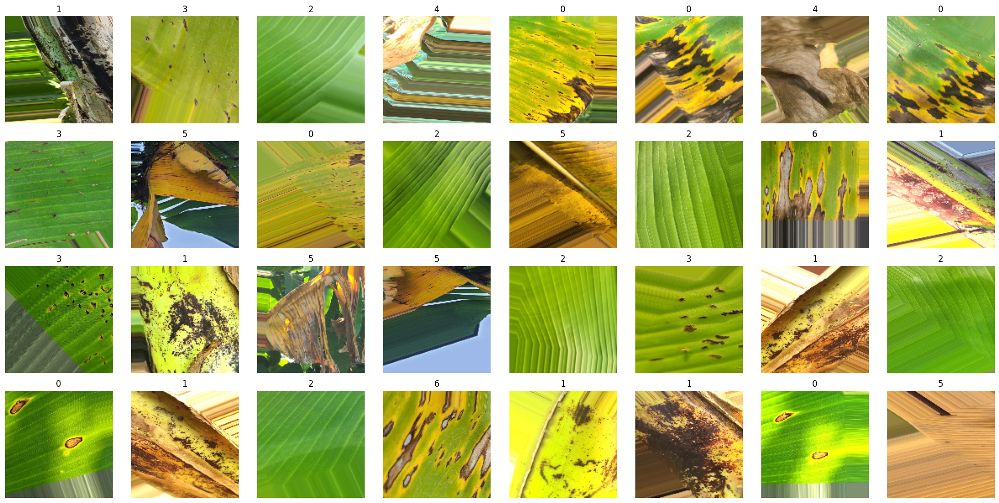

In [ ]:
images, labels = next(train_generator)

def plot_images(images_arr, labels_arr):
    fig, axes = plt.subplots(4, 8, figsize=(20, 10))
    axes = axes.flatten()
    for img, lbl, ax in zip(images_arr, labels_arr, axes):
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(np.argmax(lbl))
    plt.tight_layout()
    plt.show()

plot_images(images, labels)

In [ ]:
def apply_sobel(images_arr):
    sobel_images = []
    for img in images_arr:
        gray_img = np.dot(img[...,:3], [0.2989, 0.5870, 0.1140])
        sobel_x = sobel(gray_img, axis=0, mode='constant')
        sobel_y = sobel(gray_img, axis=1, mode='constant')
        sobel_img = np.hypot(sobel_x, sobel_y)
        sobel_images.append(sobel_img)
    return np.array(sobel_images)

sobel_images = apply_sobel(images)

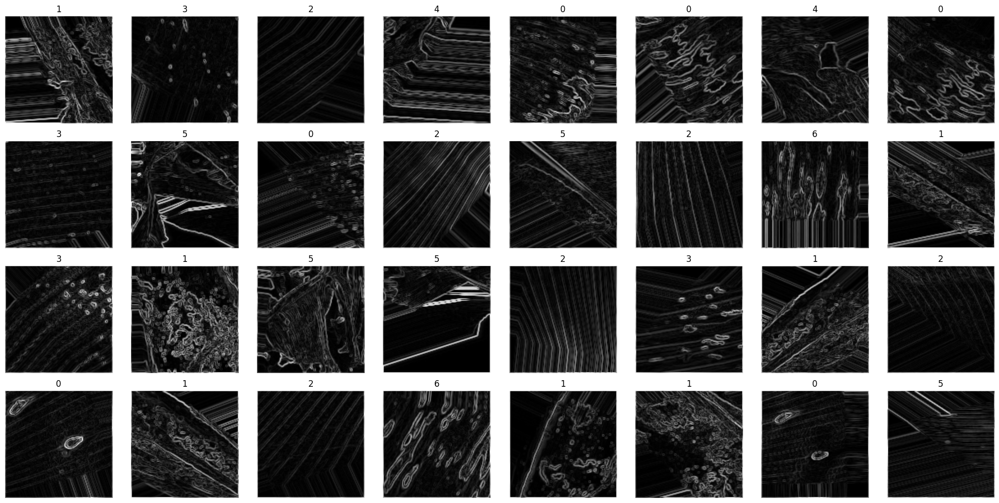

In [ ]:
def plot_sobel_images(original_images, sobel_images, labels_arr):
    fig, axes = plt.subplots(4, 8, figsize=(20, 10))
    axes = axes.flatten()
    for orig_img, sob_img, lbl, ax in zip(original_images, sobel_images, labels_arr, axes):
        ax.imshow(sob_img, cmap='gray')
        ax.axis('off')
        ax.set_title(np.argmax(lbl))
    plt.tight_layout()
    plt.show()

plot_sobel_images(images, sobel_images, labels)

In [ ]:
type(train_generator)

keras.src.legacy.preprocessing.image.DirectoryIterator

<div style="background-color: #FFEB3B; border-radius: 15px; padding: 20px; color: #4E342E; text-align: center; font-weight: 800; font-size: 24px; margin-top: 20px;">

## Building Models
</div>

## Custom CNN

In [ ]:
model_lenet = Sequential([
    Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(128, 128, 3)),
    BatchNormalization(),
    Conv2D(32, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Conv2D(64, kernel_size=(3, 3), activation='relu'),
    BatchNormalization(),
    Conv2D(64, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Conv2D(128, kernel_size=(3, 3), activation='relu'),
    BatchNormalization(),
    Conv2D(128, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Conv2D(256, kernel_size=(3, 3), activation='relu'),
    BatchNormalization(),
    Conv2D(256, kernel_size=(3, 3), activation='relu'),
    GlobalAveragePooling2D(),
    Dropout(0.5),

    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),

    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),

    Dense(7, activation='softmax')
])

In [ ]:
model_lenet.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
model_lenet.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 124, 124, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 60, 60, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 58, 58, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 29, 29, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 29, 29, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 27, 27, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 27, 27, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 25, 25, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 10, 10, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 10, 10, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 1,275,303 (4.86 MB)

 Trainable params: 1,273,575 (4.86 MB)

 Non-trainable params: 1,728 (6.75 KB)

In [ ]:
history_lenet = model_lenet.fit(train_generator, epochs=50, validation_data=val_generator, class_weight=class_weights)

Epoch 1/50


2024-07-02 20:20:25.290217: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 31758: 7.18885, expected 6.34915
2024-07-02 20:20:25.290280: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 31794: 6.79032, expected 5.95062
2024-07-02 20:20:25.290289: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 31795: 6.91364, expected 6.07395
2024-07-02 20:20:25.290297: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 31796: 7.21123, expected 6.37153
2024-07-02 20:20:25.290311: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 31809: 7.14567, expected 6.30597
2024-07-02 20:20:25.290319: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 31823: 7.30269, expected 6.46299
2024-07-02 20:20:25.290326: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 31824: 7.17199, expected 6.33229
2024-07-02 20:20:25.290334:

 1/72 ━━━━━━━━━━━━━━━━━━━━ 28:35 24s/step - accuracy: 0.1250 - loss: 2.9214 - precision: 0.1667 - recall: 0.0938

I0000 00:00:1719951636.668887     145 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


28/72 ━━━━━━━━━━━━━━━━━━━━ 8s 186ms/step - accuracy: 0.1954 - loss: 2.8385 - precision: 0.2207 - recall: 0.1229

2024-07-02 20:20:47.263330: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 16425: 4.84597, expected 4.25437
2024-07-02 20:20:47.263412: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 20279: 4.78513, expected 4.19353
2024-07-02 20:20:47.263453: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 25317: 4.89091, expected 4.29931
2024-07-02 20:20:47.263465: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 26336: 4.84597, expected 4.25437
2024-07-02 20:20:47.263489: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 30190: 4.78513, expected 4.19353
2024-07-02 20:20:47.263628: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 63557: 5.82468, expected 5.13434
2024-07-02 20:20:47.263639: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 63565: 5.34452, expected 4.65418
2024-07-02 20:20:47.263651:

70/72 ━━━━━━━━━━━━━━━━━━━━ 0s 388ms/step - accuracy: 0.2572 - loss: 2.5044 - precision: 0.2896 - recall: 0.1711

2024-07-02 20:21:08.587945: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 178: 5.39819, expected 4.73177
2024-07-02 20:21:08.588002: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 342: 5.41784, expected 4.75142
2024-07-02 20:21:08.588013: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 550: 5.14397, expected 4.47755
2024-07-02 20:21:08.588021: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 676: 5.36842, expected 4.702
2024-07-02 20:21:08.588032: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 1239: 5.5656, expected 4.89918
2024-07-02 20:21:08.588040: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 1365: 5.08219, expected 4.41577
2024-07-02 20:21:08.588053: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 2697: 5.50892, expected 4.8425
2024-07-02 20:21:08.588062: E external/loc

72/72 ━━━━━━━━━━━━━━━━━━━━ 58s 475ms/step - accuracy: 0.2602 - loss: 2.4890 - precision: 0.2928 - recall: 0.1736 - val_accuracy: 0.2759 - val_loss: 2.8645 - val_precision: 0.2881 - val_recall: 0.2460
Epoch 2/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 8s 100ms/step - accuracy: 0.3816 - loss: 1.7621 - precision: 0.4262 - recall: 0.2811 - val_accuracy: 0.2478 - val_loss: 2.7832 - val_precision: 0.2936 - val_recall: 0.2250
Epoch 3/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 8s 97ms/step - accuracy: 0.4122 - loss: 1.5579 - precision: 0.4611 - recall: 0.3085 - val_accuracy: 0.2654 - val_loss: 2.1708 - val_precision: 0.2044 - val_recall: 0.0808
Epoch 4/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 92ms/step - accuracy: 0.4280 - loss: 1.5004 - precision: 0.4989 - recall: 0.3176 - val_accuracy: 0.3972 - val_loss: 1.9095 - val_precision: 0.4726 - val_recall: 0.3480
Epoch 5/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 94ms/step - accuracy: 0.4728 - loss: 1.3236 - precision: 0.5425 - recall: 0.3540 - val_accuracy: 0.4868 - val_loss: 1.5691 - val_pr

## ResNet50 Model

In [ ]:
base_model_resnet = ResNet50(weights='imagenet', include_top=False, input_shape=(128, 128, 3))

model_resnet = Sequential([
    base_model_resnet,
    GlobalAveragePooling2D(),

    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),

    Dense(7, activation='softmax')
])

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
base_model_resnet.trainable = False
model_resnet.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
model_resnet.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ ?                      │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ ?                      │   0 (unbuilt) │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
history_resnet = model_resnet.fit(train_generator, epochs=50, validation_data=val_generator, class_weight=class_weights)

Epoch 1/50
 3/72 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.0972 - loss: 2.2882 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00  

W0000 00:00:1719952253.574825     147 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


70/72 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.2663 - loss: 1.8983 - precision_1: 0.3733 - recall_1: 0.0398

W0000 00:00:1719952269.902158     147 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


72/72 ━━━━━━━━━━━━━━━━━━━━ 36s 299ms/step - accuracy: 0.2687 - loss: 1.8927 - precision_1: 0.3783 - recall_1: 0.0408 - val_accuracy: 0.1634 - val_loss: 2.1642 - val_precision_1: 0.0000e+00 - val_recall_1: 0.0000e+00
Epoch 2/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 8s 106ms/step - accuracy: 0.4441 - loss: 1.4890 - precision_1: 0.5650 - recall_1: 0.1226 - val_accuracy: 0.0562 - val_loss: 2.1615 - val_precision_1: 0.0000e+00 - val_recall_1: 0.0000e+00
Epoch 3/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 8s 100ms/step - accuracy: 0.4532 - loss: 1.3784 - precision_1: 0.6396 - recall_1: 0.1617 - val_accuracy: 0.1406 - val_loss: 2.1085 - val_precision_1: 0.0000e+00 - val_recall_1: 0.0000e+00
Epoch 4/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 8s 98ms/step - accuracy: 0.5052 - loss: 1.3138 - precision_1: 0.6378 - recall_1: 0.2046 - val_accuracy: 0.0562 - val_loss: 2.3485 - val_precision_1: 0.0588 - val_recall_1: 0.0562
Epoch 5/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 8s 102ms/step - accuracy: 0.5402 - loss: 1.2208 - precision_1: 0.6571 - recal

## InceptionV3 Model

In [ ]:
base_model_inception = InceptionV3(weights='imagenet', include_top=False, input_shape=(128, 128, 3))


model_inception = Sequential([
    base_model_inception,
    GlobalAveragePooling2D(),

    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),

    Dense(7, activation='softmax')
])

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
base_model_inception.trainable = False
model_inception.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
model_inception.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inception_v3 (Functional)       │ ?                      │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ ?                      │   0 (unbuilt) │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_101         │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,802,784 (83.17 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 21,802,784 (83.17 MB)

In [ ]:
history_inception = model_inception.fit(train_generator, epochs=50, validation_data=val_generator, class_weight=class_weights)

Epoch 1/50
 4/72 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.1296 - loss: 2.6650 - precision_2: 0.1258 - recall_2: 0.0697

W0000 00:00:1719952990.073685     145 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - accuracy: 0.4783 - loss: 1.5986 - precision_2: 0.5824 - recall_2: 0.3895

W0000 00:00:1719953011.294896     145 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


72/72 ━━━━━━━━━━━━━━━━━━━━ 49s 417ms/step - accuracy: 0.4815 - loss: 1.5883 - precision_2: 0.5856 - recall_2: 0.3929 - val_accuracy: 0.6819 - val_loss: 1.0171 - val_precision_2: 0.7129 - val_recall_2: 0.6415
Epoch 2/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 95ms/step - accuracy: 0.7777 - loss: 0.6219 - precision_2: 0.8468 - recall_2: 0.7119 - val_accuracy: 0.7645 - val_loss: 0.6946 - val_precision_2: 0.8016 - val_recall_2: 0.7170
Epoch 3/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 8s 96ms/step - accuracy: 0.8557 - loss: 0.4422 - precision_2: 0.8945 - recall_2: 0.7983 - val_accuracy: 0.7170 - val_loss: 0.7932 - val_precision_2: 0.7665 - val_recall_2: 0.6749
Epoch 4/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 95ms/step - accuracy: 0.8787 - loss: 0.3419 - precision_2: 0.9169 - recall_2: 0.8430 - val_accuracy: 0.7715 - val_loss: 0.6056 - val_precision_2: 0.8111 - val_recall_2: 0.7469
Epoch 5/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 95ms/step - accuracy: 0.9140 - loss: 0.2524 - precision_2: 0.9420 - recall_2: 0.8872 - val_accuracy:

<div style="background-color: #FFEB3B; border-radius: 15px; padding: 20px; color: #4E342E; text-align: center; font-weight: 800; font-size: 24px; margin-top: 20px;">

## Result and Comparison
</div>

In [ ]:
def plot_performance(history, title):
    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='train_accuracy')
    plt.plot(history.history['val_accuracy'], label='val_accuracy')
    plt.title(f'{title} Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='train_loss')
    plt.plot(history.history['val_loss'], label='val_loss')
    plt.title(f'{title} Loss')
    plt.legend()

    plt.show()

In [ ]:
def evaluate_model(model, generator):
    y_true = generator.classes
    y_pred = model.predict(generator)
    y_pred_classes = np.argmax(y_pred, axis=1)

    cm = confusion_matrix(y_true, y_pred_classes)
    cr = classification_report(y_true, y_pred_classes, target_names=generator.class_indices.keys())

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=generator.class_indices.keys(), yticklabels=generator.class_indices.keys())
    plt.title('Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

    print('Classification Report:')
    print(cr)

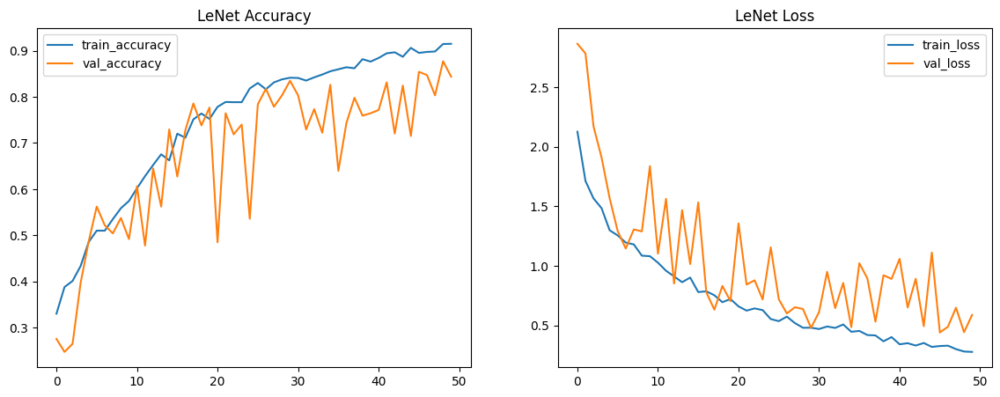

In [ ]:
plot_performance(history_lenet, 'LeNet')

18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 114ms/step


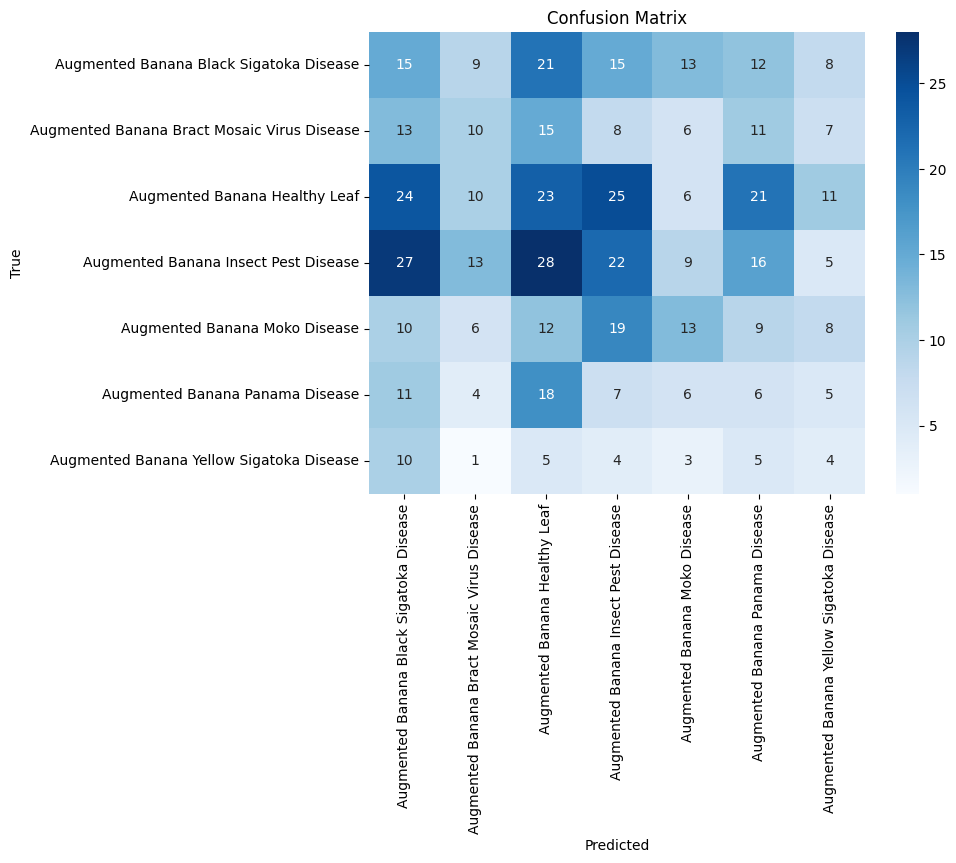

Classification Report:
                                             precision    recall  f1-score   support

    Augmented Banana Black Sigatoka Disease       0.14      0.16      0.15        93
Augmented Banana Bract Mosaic Virus Disease       0.19      0.14      0.16        70
              Augmented Banana Healthy Leaf       0.19      0.19      0.19       120
       Augmented Banana Insect Pest Disease       0.22      0.18      0.20       120
              Augmented Banana Moko Disease       0.23      0.17      0.20        77
            Augmented Banana Panama Disease       0.07      0.11      0.09        57
   Augmented Banana Yellow Sigatoka Disease       0.08      0.12      0.10        32

                                   accuracy                           0.16       569
                                  macro avg       0.16      0.15      0.15       569
                               weighted avg       0.18      0.16      0.17       569



In [ ]:
evaluate_model(model_lenet, val_generator)

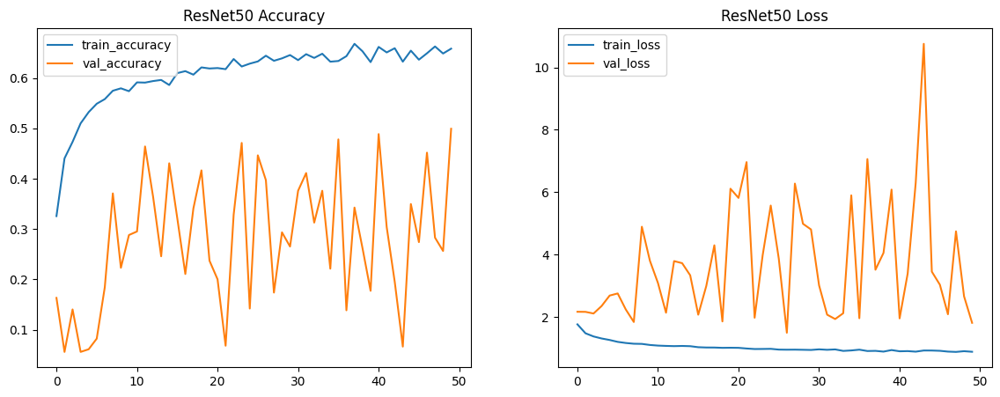

In [ ]:
plot_performance(history_resnet, 'ResNet50')

 4/18 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step

W0000 00:00:1719952944.428253     145 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 285ms/step


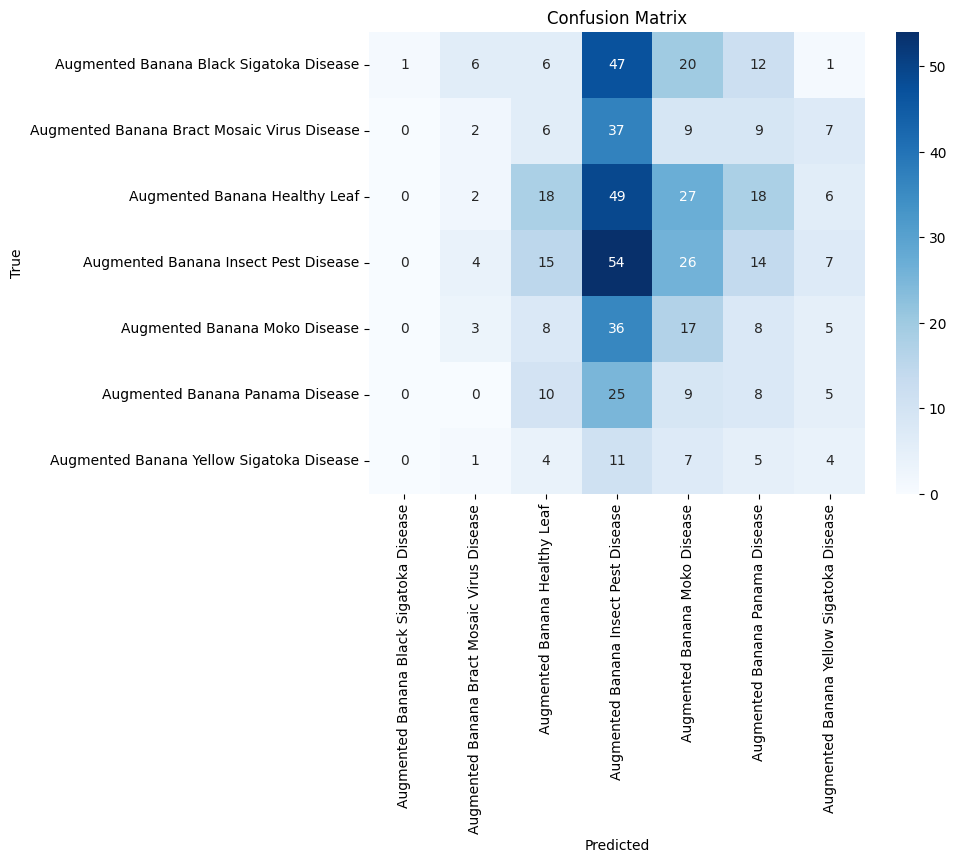

Classification Report:
                                             precision    recall  f1-score   support

    Augmented Banana Black Sigatoka Disease       1.00      0.01      0.02        93
Augmented Banana Bract Mosaic Virus Disease       0.11      0.03      0.05        70
              Augmented Banana Healthy Leaf       0.27      0.15      0.19       120
       Augmented Banana Insect Pest Disease       0.21      0.45      0.28       120
              Augmented Banana Moko Disease       0.15      0.22      0.18        77
            Augmented Banana Panama Disease       0.11      0.14      0.12        57
   Augmented Banana Yellow Sigatoka Disease       0.11      0.12      0.12        32

                                   accuracy                           0.18       569
                                  macro avg       0.28      0.16      0.14       569
                               weighted avg       0.32      0.18      0.15       569



In [ ]:
evaluate_model(model_resnet, val_generator)

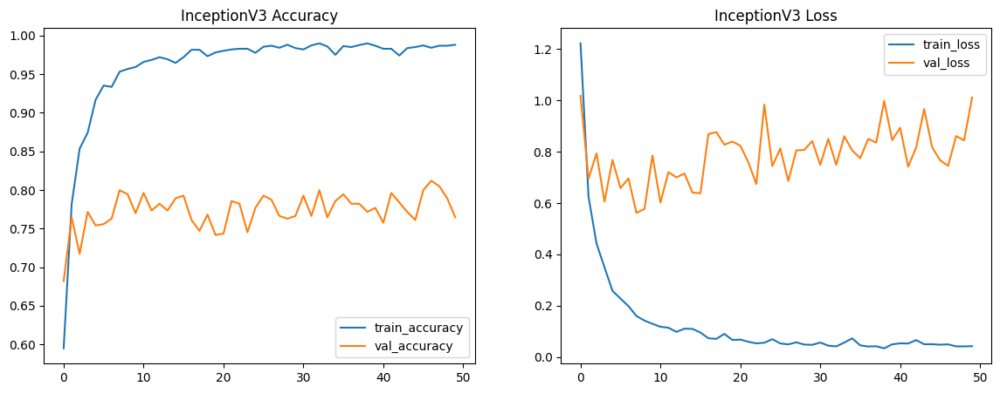

In [ ]:
plot_performance(history_inception, 'InceptionV3')

 4/18 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step

W0000 00:00:1719953574.947176     145 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


18/18 ━━━━━━━━━━━━━━━━━━━━ 12s 404ms/step


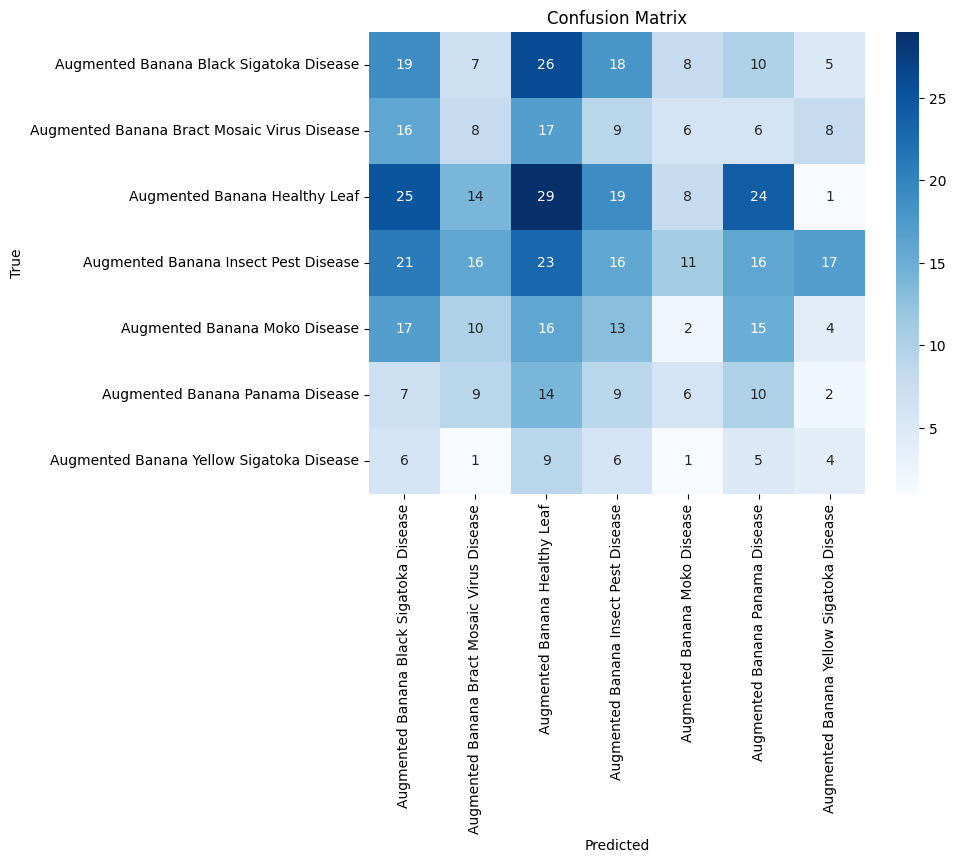

Classification Report:
                                             precision    recall  f1-score   support

    Augmented Banana Black Sigatoka Disease       0.17      0.20      0.19        93
Augmented Banana Bract Mosaic Virus Disease       0.12      0.11      0.12        70
              Augmented Banana Healthy Leaf       0.22      0.24      0.23       120
       Augmented Banana Insect Pest Disease       0.18      0.13      0.15       120
              Augmented Banana Moko Disease       0.05      0.03      0.03        77
            Augmented Banana Panama Disease       0.12      0.18      0.14        57
   Augmented Banana Yellow Sigatoka Disease       0.10      0.12      0.11        32

                                   accuracy                           0.15       569
                                  macro avg       0.14      0.15      0.14       569
                               weighted avg       0.15      0.15      0.15       569



In [ ]:
evaluate_model(model_inception, val_generator)

In [ ]:
model_lenet.save('model_lenet.h5')

In [ ]:
model_resnet.save('model_resnet.h5')

In [ ]:
model_inception.save('model_inception.h5')

In [ ]:
def preprocess_image(image_path, target_size):
    img = load_img(image_path, target_size=target_size)
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array / 255.0
    return img_array

class_mapping = {
    0: "Banana Black Sigatoka Disease",
    1: "Banana Bract Mosaic Virus Disease",
    2: "Banana Healthy Leaf",
    3: "Banana Insect Pest Disease",
    4: "Banana Moko Disease",
    5: "Banana Panama Disease",
    6: "Banana Yellow Sigatoka Disease"
}

# Function to predict using each model and aggregate predictions
def predict_with_voting(image_path):
    input_size = (128, 128)

    img_lenet = preprocess_image(image_path, input_size)
    img_resnet = preprocess_image(image_path, input_size)
    img_inception = preprocess_image(image_path, input_size)

    # Step 1: Make predictions using each model
    pred_lenet = model_lenet.predict(img_lenet)
    pred_resnet = model_resnet.predict(img_resnet)
    pred_inception = model_inception.predict(img_inception)

    # Step 2: Aggregate predicted probabilities (soft voting)
    # Soft voting: Average the predicted probabilities
    final_pred_prob = (pred_lenet + pred_resnet + pred_inception) / 3

    # Step 3: Predict class based on the aggregated probabilities
    final_pred_class = np.argmax(final_pred_prob, axis=1)

    # Map predicted class indices to disease names
    final_pred_disease = [class_mapping[class_index] for class_index in final_pred_class]

    return final_pred_disease

image_path = '/kaggle/input/banana-disease-recognition-dataset/Banana Disease Recognition Dataset/Augmented images/Augmented images/Augmented Banana Healthy Leaf/Augmented Banana Healthy Leaf (102).jpg'
predicted_class = predict_with_voting(image_path)
print("Predicted Class:", predicted_class)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
Predicted Class: ['Banana Healthy Leaf']


In [ ]:
image_path = '/kaggle/input/banana-disease-recognition-dataset/Banana Disease Recognition Dataset/Augmented images/Augmented images/Augmented Banana Panama Disease/Augmented Banana Panama Disease (10).jpg'
predicted_class = predict_with_voting(image_path)
print("Predicted Class:", predicted_class)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
Predicted Class: ['Banana Panama Disease']


In [ ]:
import os
import zipfile

zip_path = "/content/Banana Disease Recognition Dataset.zip"

print("File exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("File size:", os.path.getsize(zip_path), "bytes")
    print("Valid ZIP:", zipfile.is_zipfile(zip_path))

    try:
        with zipfile.ZipFile(zip_path, "r") as z:
            print("Number of files:", len(z.namelist()))
            print("ZIP test:", z.testzip())
    except Exception as e:
        print("ZIP error:", repr(e))

File exists: True
File size: 127800953 bytes
Valid ZIP: True
Number of files: 3283
ZIP test: None


In [ ]:
import os
import zipfile

zip_path = "/content/Banana Disease Recognition Dataset.zip"
extract_path = "/content/banana_dataset_extracted"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    # Check for filenames that might cause extraction errors
    bad_names = [
        name for name in z.namelist()
        if "\x00" in name or name.startswith("/")
    ]
    print("Suspicious paths:", bad_names[:10])

    # Extract one file at a time to identify any problematic entry
    extracted = 0
    for name in z.namelist():
        try:
            z.extract(name, extract_path)
            extracted += 1
        except Exception as e:
            print("Failed file:", repr(name))
            print("Error:", repr(e))
            break

    print("Files extracted:", extracted, "of", len(z.namelist()))

Suspicious paths: []
Files extracted: 3283 of 3283


In [ ]:
import os

extract_path = "/content/banana_dataset_extracted"

for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)

    # Show only the first few folder levels
    if level <= 3:
        indent = "  " * level
        print(f"{indent}{os.path.basename(root)}/")

        if level == 3:
            dirs[:] = []

        for filename in files[:5]:
            print(f"{indent}  {filename}")

    if level >= 3:
        dirs[:] = []

banana_dataset_extracted/
  Banana Disease Recognition Dataset/
    Augmented images/
      Augmented images/
    Original Images/
      Original Images/


In [ ]:
import os

dataset_path = (
    "/content/banana_dataset_extracted/"
    "Banana Disease Recognition Dataset"
)

for folder in ["Original Images", "Augmented images"]:
    folder_path = os.path.join(dataset_path, folder)

    print(f"\n--- {folder} ---")

    for root, dirs, files in os.walk(folder_path):
        dirs.sort()
        relative_path = os.path.relpath(root, folder_path)
        image_count = sum(
            f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
            for f in files
        )

        if dirs or image_count:
            print(f"{relative_path}: {image_count} images")


--- Original Images ---
.: 0 images
Original Images: 0 images
Original Images/Banana Black Sigatoka Disease: 67 images
Original Images/Banana Bract Mosaic Virus Disease: 50 images
Original Images/Banana Healthy Leaf: 86 images
Original Images/Banana Insect Pest Disease: 86 images
Original Images/Banana Moko Disease: 55 images
Original Images/Banana Panama Disease: 41 images
Original Images/Banana Yellow Sigatoka Disease: 23 images

--- Augmented images ---
.: 0 images
Augmented images: 0 images
Augmented images/Augmented Banana Black Sigatoka Disease: 469 images
Augmented images/Augmented Banana Bract Mosaic Virus Disease: 350 images
Augmented images/Augmented Banana Healthy Leaf: 602 images
Augmented images/Augmented Banana Insect Pest Disease: 602 images
Augmented images/Augmented Banana Moko Disease: 385 images
Augmented images/Augmented Banana Panama Disease: 287 images
Augmented images/Augmented Banana Yellow Sigatoka Disease: 161 images


In [ ]:
import os
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import load_img, img_to_array

dataset_path = (
    "/content/banana_dataset_extracted/"
    "Banana Disease Recognition Dataset/"
    "Original Images/Original Images"
)

img_size = (128, 128)
images = []
labels = []

for class_name in sorted(os.listdir(dataset_path)):
    class_path = os.path.join(dataset_path, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
            image_path = os.path.join(class_path, filename)

            try:
                img = load_img(image_path, target_size=img_size)
                images.append(img_to_array(img) / 255.0)
                labels.append(class_name)
            except Exception as e:
                print("Skipping:", image_path, e)

X = np.array(images, dtype=np.float32)

encoder = LabelEncoder()
y = encoder.fit_transform(labels)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Total images:", len(X))
print("Training images:", len(X_train))
print("Testing images:", len(X_test))
print("\nDisease classes:")
for i, name in enumerate(encoder.classes_):
    print(i, "-", name)

print("\nImage shape:", X_train.shape[1:])

Total images: 408
Training images: 326
Testing images: 82

Disease classes:
0 - Banana Black Sigatoka Disease
1 - Banana Bract Mosaic Virus Disease
2 - Banana Healthy Leaf
3 - Banana Insect Pest Disease
4 - Banana Moko Disease
5 - Banana Panama Disease
6 - Banana Yellow Sigatoka Disease

Image shape: (128, 128, 3)


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

num_classes = len(encoder.classes_)

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,543 (12.61 MB)

 Trainable params: 3,305,543 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=25,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 13s 588ms/step - accuracy: 0.2808 - loss: 1.8781 - val_accuracy: 0.3788 - val_loss: 1.6091
Epoch 2/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 10s 591ms/step - accuracy: 0.4115 - loss: 1.5198 - val_accuracy: 0.3788 - val_loss: 1.4198
Epoch 3/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 8s 478ms/step - accuracy: 0.5000 - loss: 1.3466 - val_accuracy: 0.4848 - val_loss: 1.1855
Epoch 4/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 10s 573ms/step - accuracy: 0.5000 - loss: 1.2504 - val_accuracy: 0.5909 - val_loss: 1.0345
Epoch 5/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 10s 566ms/step - accuracy: 0.5615 - loss: 1.1188 - val_accuracy: 0.5455 - val_loss: 1.0784
Epoch 6/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 483ms/step - accuracy: 0.5577 - loss: 1.1276 - val_accuracy: 0.6667 - val_loss: 0.9086
Epoch 7/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 10s 472ms/step - accuracy: 0.6385 - loss: 0.9384 - val_accuracy: 0.5909 - val_loss: 0.9475
Epoch 8/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 10s 577ms/step - accuracy: 0.6231 - loss: 0.9995 - val_accura

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")

Test accuracy: 70.73%
Test loss: 0.9055


In [ ]:
model.save("/content/banana_leaf_disease_model.keras")
print("Model saved successfully!")

Model saved successfully!


3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 783ms/step
                                   precision    recall  f1-score   support

    Banana Black Sigatoka Disease       0.70      0.50      0.58        14
Banana Bract Mosaic Virus Disease       0.69      0.90      0.78        10
              Banana Healthy Leaf       0.65      1.00      0.79        17
       Banana Insect Pest Disease       0.82      0.53      0.64        17
              Banana Moko Disease       0.71      0.91      0.80        11
            Banana Panama Disease       1.00      0.38      0.55         8
   Banana Yellow Sigatoka Disease       0.60      0.60      0.60         5

                         accuracy                           0.71        82
                        macro avg       0.74      0.69      0.68        82
                     weighted avg       0.74      0.71      0.69        82



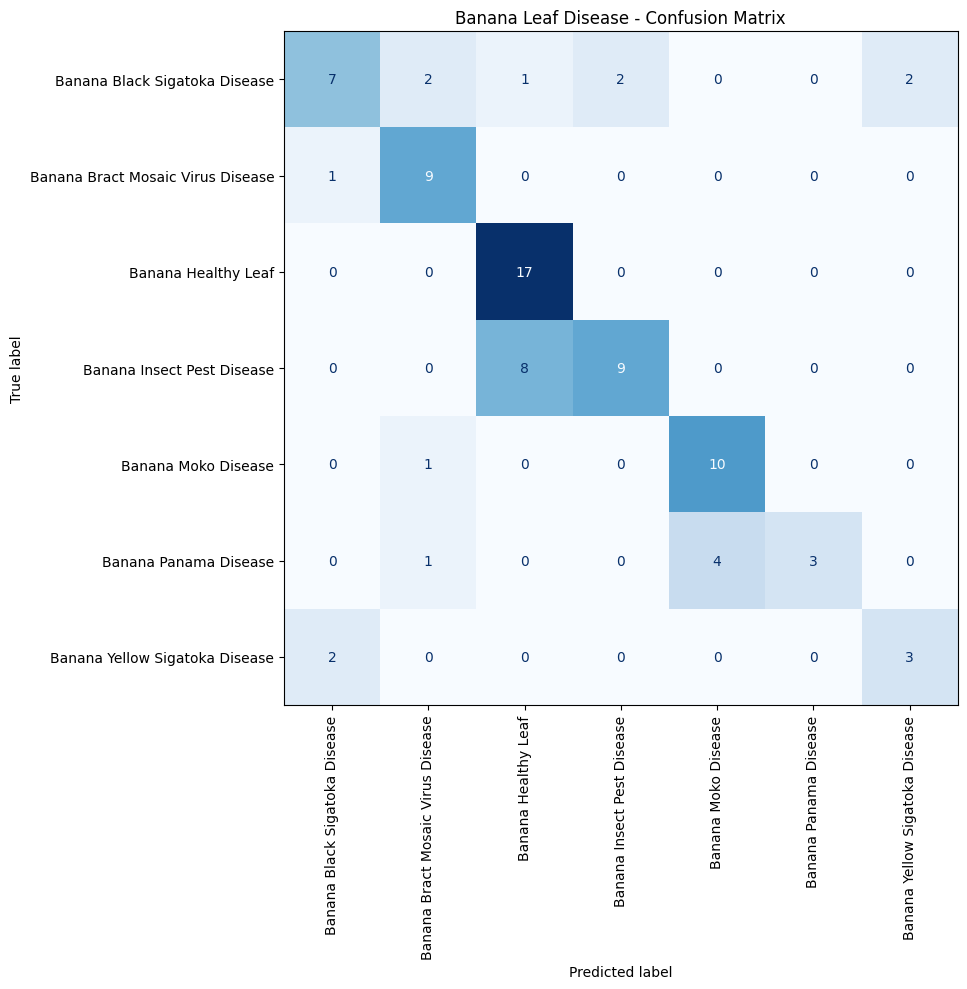

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predict the test images
probabilities = model.predict(X_test)
y_pred = np.argmax(probabilities, axis=1)

# Report precision, recall and F1-score
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(encoder.classes_))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
)

fig, ax = plt.subplots(figsize=(12, 10))
display.plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False)
plt.title("Banana Leaf Disease - Confusion Matrix")
plt.tight_layout()
plt.show()

Saving Yellow Sigatoka Disease (14).jpg to Yellow Sigatoka Disease (14).jpg


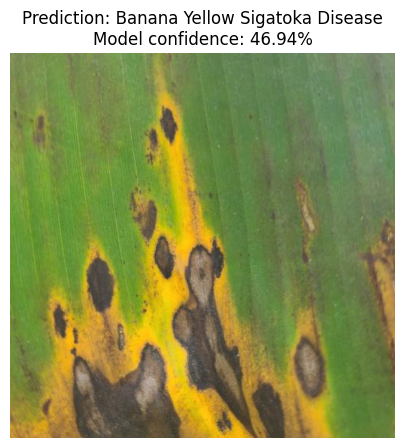

Predicted category: Banana Yellow Sigatoka Disease
Model confidence: 46.94%


In [ ]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

# Upload or fallback to sample leaf
uploaded = {}
try:
    from google.colab import files
    uploaded = files.upload()
except Exception:
    pass

if not uploaded:
    sample_files = list(Path('.').glob('sample_*.jpg')) or list(Path('data').rglob('*.jpg'))
    if sample_files:
        uploaded = {str(sample_files[0]): None}

for filename in uploaded:
    print(f'Analyzing image: {filename}')
    img = load_img(filename, target_size=(128, 128))
    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    probabilities = model.predict(img_array, verbose=0)[0]
    predicted_index = np.argmax(probabilities)
    predicted_class = encoder.classes_[predicted_index]
    confidence = probabilities[predicted_index] * 100

    plt.figure(figsize=(5, 5))
    plt.imshow(load_img(filename))
    plt.axis('off')
    plt.title(f'Prediction: {predicted_class}
Model confidence: {confidence:.2f}%')
    plt.show()

    print('Predicted category:', predicted_class)
    print(f'Model confidence: {confidence:.2f}%')


In [ ]:
model.save("/content/banana_leaf_disease_model.keras")
print("Model saved successfully!")

Model saved successfully!


In [ ]:
try:
    from google.colab import files
    files.download("/content/banana_leaf_disease_model.keras")
except Exception:
    print("Colab download skipped outside Google Colab environment.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

num_classes = len(encoder.classes_)

# Apply random transformations only during training
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
])

improved_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    data_augmentation,

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation="softmax")
])

improved_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_improved = improved_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 20s 961ms/step - accuracy: 0.4000 - loss: 1.6433 - val_accuracy: 0.2424 - val_loss: 1.9148
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 16s 946ms/step - accuracy: 0.4654 - loss: 1.2998 - val_accuracy: 0.3636 - val_loss: 1.8299
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 16s 936ms/step - accuracy: 0.5962 - loss: 1.0603 - val_accuracy: 0.3333 - val_loss: 1.7774
Epoch 4/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 16s 935ms/step - accuracy: 0.6077 - loss: 1.0302 - val_accuracy: 0.2727 - val_loss: 1.8628
Epoch 5/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 16s 952ms/step - accuracy: 0.5923 - loss: 1.0078 - val_accuracy: 0.2576 - val_loss: 1.9006
Epoch 6/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 20s 948ms/step - accuracy: 0.6423 - loss: 0.9062 - val_accuracy: 0.2576 - val_loss: 2.0661
Epoch 7/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 21s 921ms/step - accuracy: 0.6769 - loss: 0.8215 - val_accuracy: 0.2576 - val_loss: 2.0361
Epoch 8/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 15s 908ms/step - accuracy: 0.6846 - loss: 0.8703 - val_accu

In [ ]:
test_loss, test_accuracy = improved_model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Improved test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")

Improved test accuracy: 32.93%
Test loss: 1.8061


In [ ]:
improved_model.save(
    "/content/banana_leaf_disease_improved.keras"
)
print("Improved model saved!")

Improved model saved!


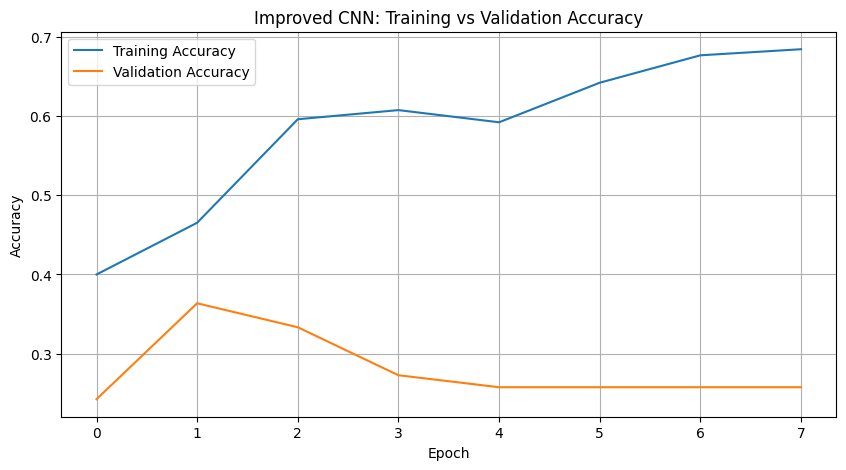

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history_improved.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    history_improved.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Improved CNN: Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

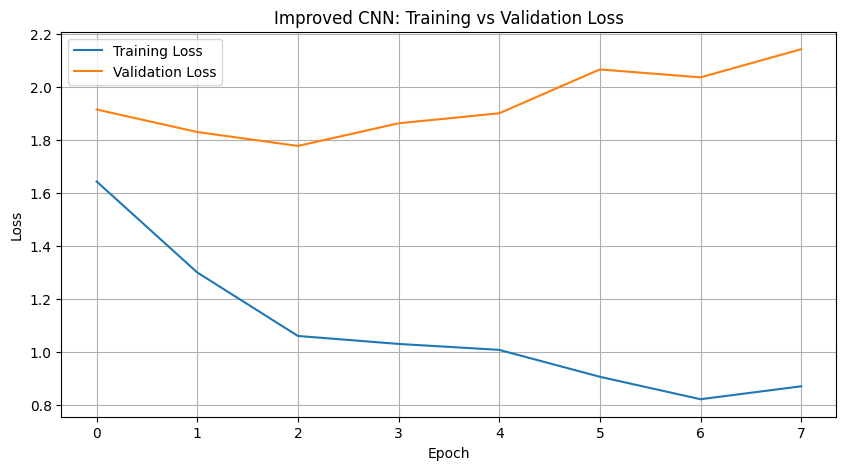

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_improved.history["loss"],
    label="Training Loss"
)
plt.plot(
    history_improved.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Improved CNN: Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import classification_report

y_pred_original = np.argmax(
    model.predict(X_test, verbose=0),
    axis=1
)

print(classification_report(
    y_test,
    y_pred_original,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

                                   precision    recall  f1-score   support

    Banana Black Sigatoka Disease       0.70      0.50      0.58        14
Banana Bract Mosaic Virus Disease       0.69      0.90      0.78        10
              Banana Healthy Leaf       0.65      1.00      0.79        17
       Banana Insect Pest Disease       0.82      0.53      0.64        17
              Banana Moko Disease       0.71      0.91      0.80        11
            Banana Panama Disease       1.00      0.38      0.55         8
   Banana Yellow Sigatoka Disease       0.60      0.60      0.60         5

                         accuracy                           0.71        82
                        macro avg       0.74      0.69      0.68        82
                     weighted avg       0.74      0.71      0.69        82



In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Pretrained feature extractor
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(128, 128, 3))

# MobileNetV2 expects preprocessing to [-1, 1]
x = layers.Rescaling(
    scale=2.0, offset=-1.0
)(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    len(encoder.classes_),
    activation="softmax"
)(x)

transfer_model = models.Model(inputs, outputs)

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_transfer = transfer_model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 16s 531ms/step - accuracy: 0.1038 - loss: 3.3312 - val_accuracy: 0.1061 - val_loss: 2.5289
Epoch 2/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 244ms/step - accuracy: 0.1231 - loss: 2.6803 - val_accuracy: 0.1364 - val_loss: 2.1849
Epoch 3/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 268ms/step - accuracy: 0.1885 - loss: 2.4239 - val_accuracy: 0.2273 - val_loss: 1.9543
Epoch 4/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 220ms/step - accuracy: 0.2692 - loss: 2.1051 - val_accuracy: 0.3030 - val_loss: 1.7750
Epoch 5/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 203ms/step - accuracy: 0.2962 - loss: 2.0414 - val_accuracy: 0.3636 - val_loss: 1.6122
Epoch 6/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 244ms/step - accuracy: 0.3962 - loss: 1.7485 - val_accuracy: 0.4242 - val_loss: 1.4879
Epoch 7/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 262ms/step - accuracy: 0.4346 - loss: 1.6209 - val_accuracy: 0.4848 - val_loss: 1.3715
Epoch 8/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 204ms/step - 

In [ ]:
test_loss, test_accuracy = transfer_model.evaluate(
    X_test, y_test, verbose=0
)

print(f"MobileNetV2 test accuracy: {test_accuracy * 100:.2f}%")
print(f"MobileNetV2 test loss: {test_loss:.4f}")

MobileNetV2 test accuracy: 79.27%
MobileNetV2 test loss: 0.6689


In [ ]:
try:
    from google.colab import files
    files.download("/content/banana_leaf_disease_model.keras")
except Exception:
    print("Colab download skipped outside Google Colab environment.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
transfer_model.save(
    "/content/banana_leaf_disease_model.keras"
)

print("MobileNetV2 model saved successfully!")

MobileNetV2 model saved successfully!


Saving mk.jpg to mk.jpg
Predicted category: Banana Moko Disease
Model confidence: 84.12%


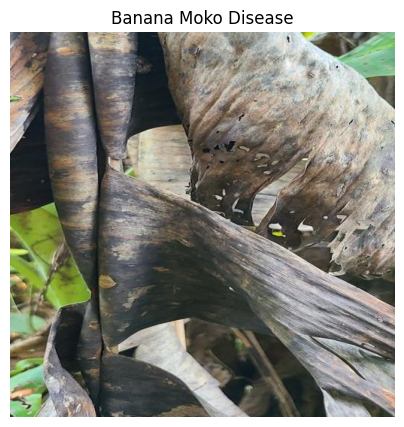

In [ ]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

uploaded = {}
try:
    from google.colab import files
    uploaded = files.upload()
except Exception:
    pass

if not uploaded:
    sample_files = list(Path('.').glob('sample_*.jpg')) or list(Path('data').rglob('*.jpg'))
    if sample_files:
        uploaded = {str(sample_files[0]): None}

for filename in uploaded:
    img = load_img(filename, target_size=(128, 128))
    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    predictions = transfer_model.predict(img_array, verbose=0)[0]
    index = np.argmax(predictions)

    print('Predicted category:', encoder.classes_[index])
    print(f'Model confidence: {predictions[index] * 100:.2f}%')

    plt.figure(figsize=(5, 5))
    plt.imshow(load_img(filename))
    plt.axis('off')
    plt.title(encoder.classes_[index])
    plt.show()


In [ ]:
from pathlib import Path

for p in Path("/content").rglob("Banana Black Sigatoka Disease"):
    print("Found image class folder:", p)

In [ ]:
import zipfile
from pathlib import Path

zip_path = Path("/content/Banana Disease Recognition Dataset.zip")
extract_path = Path("/content/banana_extracted")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Extraction complete!")
print("Files extracted to:", extract_path)

Extraction complete!
Files extracted to: /content/banana_extracted


In [ ]:
import pandas as pd
from pathlib import Path

extract_path = Path("/content/banana_extracted")

# Locate the original image class folder automatically
class_folders = list(
    extract_path.rglob("Banana Black Sigatoka Disease")
)

if not class_folders:
    raise FileNotFoundError(
        "Disease class folder not found. Check the ZIP contents."
    )

DATASET_DIR = class_folders[0].parent

records = []
valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for class_dir in sorted(DATASET_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    for img_path in class_dir.iterdir():
        if img_path.suffix.lower() in valid_extensions:
            records.append({
                "sample_id": img_path.stem,
                "image_path": str(img_path),
                "label": class_dir.name
            })

labels_df = pd.DataFrame(records)

print("Dataset directory:", DATASET_DIR)
print("Total images:", len(labels_df))
print("\nImages per class:")
print(labels_df["label"].value_counts())
display(labels_df.head())

Dataset directory: /content/banana_extracted/Banana Disease Recognition Dataset/Original Images/Original Images
Total images: 408

Images per class:
label
Banana Healthy Leaf                  86
Banana Insect Pest Disease           86
Banana Black Sigatoka Disease        67
Banana Moko Disease                  55
Banana Bract Mosaic Virus Disease    50
Banana Panama Disease                41
Banana Yellow Sigatoka Disease       23
Name: count, dtype: int64


,sample_id,image_path,label
0,Black Sigatoka Disease (9),/content/banana_extracted/Banana Disease Recog...,Banana Black Sigatoka Disease
1,Black Sigatoka Disease (30),/content/banana_extracted/Banana Disease Recog...,Banana Black Sigatoka Disease
2,Black Sigatoka Disease (53),/content/banana_extracted/Banana Disease Recog...,Banana Black Sigatoka Disease
3,Black Sigatoka Disease (43),/content/banana_extracted/Banana Disease Recog...,Banana Black Sigatoka Disease
4,Black Sigatoka Disease (41),/content/banana_extracted/Banana Disease Recog...,Banana Black Sigatoka Disease


In [ ]:
import pandas as pd

rows = []

for sample_id in labels_df["sample_id"].astype(str):
    for step in range(8):
        rows.append({
            "sample_id": sample_id,
            "step": step,
            "temperature_c": None,
            "relative_humidity_pct": None,
            "rainfall_mm": None,
            "soil_moisture": None,
            "soil_ph": None,
            "season": None
        })

environment_template = pd.DataFrame(rows)

output_path = "/content/banana_environment_template.csv"
environment_template.to_csv(output_path, index=False)

print("Images:", len(labels_df))
print("Environmental records:", len(environment_template))
print("Saved to:", output_path)

from google.colab import files
files.download(output_path)

Images: 408
Environmental records: 3264
Saved to: /content/banana_environment_template.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
USE_MULTIMODAL = True

ENVIRONMENT_CSV = Path(
    "/content/drive/MyDrive/banana_utm_ai/environment.csv"
)

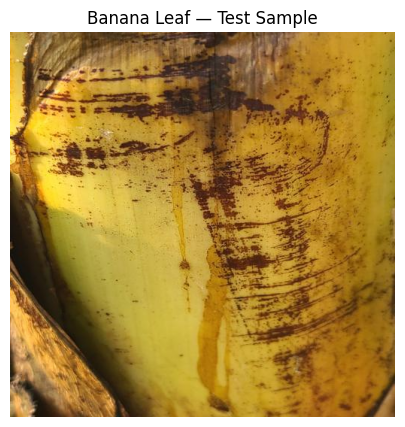

BANANA LEAF DISEASE REPORT — TEST
Image ID: Bract Mosaic Virus Disease (14)
Dataset label: Banana Bract Mosaic Virus Disease
Image path: /content/banana_extracted/Banana Disease Recognition Dataset/Original Images/Original Images/Banana Bract Mosaic Virus Disease/Bract Mosaic Virus Disease (14).jpg
Environmental readings: NOT YET FILLED
Model prediction: Run trained model to obtain
Confidence and class probabilities.


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# Select one real image from your loaded dataset
sample = labels_df.sample(1, random_state=42).iloc[0]
img = Image.open(sample["image_path"]).convert("RGB")

plt.figure(figsize=(6, 5))
plt.imshow(img)
plt.title("Banana Leaf — Test Sample")
plt.axis("off")
plt.show()

print("=" * 50)
print("BANANA LEAF DISEASE REPORT — TEST")
print("=" * 50)
print("Image ID:", sample["sample_id"])
print("Dataset label:", sample["label"])
print("Image path:", sample["image_path"])
print("Environmental readings: NOT YET FILLED")
print("Model prediction: Run trained model to obtain")
print("Confidence and class probabilities.")
print("=" * 50)

In [ ]:

from pathlib import Path

# Check model-related variables already in memory
print("Model variables currently loaded:")
for name, obj in list(globals().items()):
    if any(word in name.lower() for word in ["model", "encoder", "classifier"]):
        if not name.startswith("_"):
            print(" -", name, ":", type(obj).__name__)

# Search common Colab locations for saved model files
print("\nSaved model files found:")
roots = [Path("/content"), Path("/content/drive/MyDrive")]
extensions = {".keras", ".h5", ".pb"}

found = []
for root in roots:
    if root.exists():
        for p in root.rglob("*"):
            if p.is_file() and (
                p.suffix.lower() in {".keras", ".h5"}
                or p.name == "saved_model.pb"
            ):
                found.append(str(p))
                if len(found) >= 40:
                    break
    if len(found) >= 40:
        break

if found:
    print("\n".join(found))
else:
    print("No saved model files found in the searched locations.")


Model variables currently loaded:

Saved model files found:
No saved model files found in the searched locations.


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training model...
Epoch 1/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 26s 680ms/step - accuracy: 0.3129 - loss: 2.1354 - val_accuracy: 0.7317 - val_loss: 0.9149
Epoch 2/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 472ms/step - accuracy: 0.7546 - loss: 0.7282 - val_accuracy: 0.8293 - val_loss: 0.4386
Epoch 3/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 474ms/step - accuracy: 0.8773 - loss: 0.3921 - val_accuracy: 0.8780 - val_loss: 0.3341
Epoch 4/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 392ms/step - accuracy: 0.9049 - loss: 0.2950 - val_accuracy: 0.9390 - val_loss: 0.2584
Epoch 5/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 439ms/step - accuracy: 0.9325 - loss: 0.2185 - val_accuracy: 0.9268 - val_loss: 0.2281

Validation accuracy: 92.68%
Note: validation accuracy is an estimate, not a guarantee.

BANANA LEAF DISEASE REPORT
Image ID: Bract Mosaic Virus Disease (14)
Actual dataset label: Banana Bract Mosaic Virus Disease
Predicted disease: Banana Bract Mosaic Virus Disease
Model confidence: 98.68%
Env

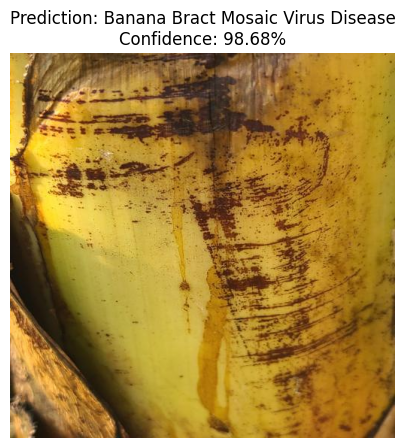

Saved model to /content/banana_leaf_model.keras


In [ ]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, Model

# Check the dataset
assert "labels_df" in globals(), (
    "labels_df is missing. Run your dataset-loading cell first."
)

df = labels_df.dropna(subset=["image_path", "label"]).copy()
df = df[df["image_path"].map(lambda p: __import__("os").path.isfile(p))]
assert len(df) > 0, "No valid image files were found."

# Encode the seven disease classes
encoder = LabelEncoder()
df["label_id"] = encoder.fit_transform(df["label"])

train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label_id"]
)

IMG_SIZE = 160
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(encoder.classes_)

def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = preprocess_input(image)
    return image, label

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        frame["image_path"].values,
        frame["label_id"].values.astype("int32")
    ))
    if training:
        ds = ds.shuffle(len(frame), seed=42)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)

# Build a transfer-learning model
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

transfer_model = Model(inputs, outputs)

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Training model...")
history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    verbose=1
)

# Evaluate on held-out validation data
val_loss, val_accuracy = transfer_model.evaluate(val_ds, verbose=0)
print(f"\nValidation accuracy: {val_accuracy * 100:.2f}%")
print("Note: validation accuracy is an estimate, not a guarantee.")

# Predict the requested sample
target = df[df["sample_id"] == "Bract Mosaic Virus Disease (14)"]
if target.empty:
    target = df.sample(1, random_state=42)
sample = target.iloc[0]

original = Image.open(sample["image_path"]).convert("RGB")
resized = original.resize((IMG_SIZE, IMG_SIZE))
arr = preprocess_input(
    np.asarray(resized, dtype=np.float32)
)
probabilities = transfer_model.predict(arr[None, ...], verbose=0)[0]

order = np.argsort(probabilities)[::-1]
best = int(order[0])

print("\n" + "=" * 55)
print("BANANA LEAF DISEASE REPORT")
print("=" * 55)
print("Image ID:", sample["sample_id"])
print("Actual dataset label:", sample["label"])
print("Predicted disease:", encoder.classes_[best])
print(f"Model confidence: {probabilities[best] * 100:.2f}%")
print("Environmental readings: NOT AVAILABLE")
print("\nCLASS PROBABILITIES:")

for i in order:
    print(f"{encoder.classes_[i]:40s} {probabilities[i] * 100:6.2f}%")

print("=" * 55)

plt.figure(figsize=(6, 5))
plt.imshow(original)
plt.title(
    f"Prediction: {encoder.classes_[best]}\n"
    f"Confidence: {probabilities[best] * 100:.2f}%"
)
plt.axis("off")
plt.show()

# Save the trained model for later use
transfer_model.save("/content/banana_leaf_model.keras")
print("Saved model to /content/banana_leaf_model.keras")


Model layers:
input_layer_1 InputLayer
mobilenetv2_1.00_160 Functional
global_average_pooling2d GlobalAveragePooling2D
dropout Dropout
dense Dense


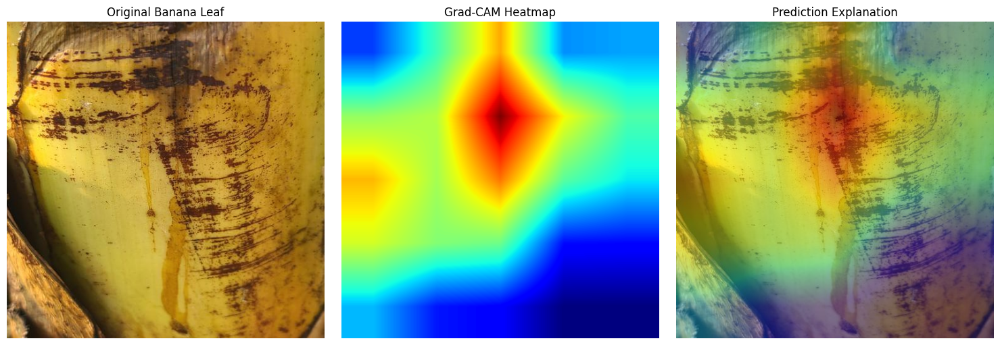

Predicted disease: Banana Bract Mosaic Virus Disease
Confidence: 98.68%


In [ ]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image

# Get the trained model's layers
print("Model layers:")
for layer in transfer_model.layers:
    print(layer.name, type(layer).__name__)

# Find the MobileNetV2 backbone automatically
base_model = next(
    layer for layer in transfer_model.layers
    if isinstance(layer, tf.keras.Model)
    and "mobilenet" in layer.name.lower()
)

# Use the last convolutional feature map
last_conv_layer = base_model.get_layer("out_relu")

# Create a feature extractor that outputs the feature map
feature_extractor = tf.keras.Model(
    inputs=base_model.inputs,
    outputs=last_conv_layer.output
)

# Identify the layers after the backbone
classifier_layers = transfer_model.layers[
    transfer_model.layers.index(base_model) + 1:
]

def classify_features(features):
    x = features
    for layer in classifier_layers:
        x = layer(x)
    return x

# Prepare the selected image
img = Image.open(sample["image_path"]).convert("RGB")
img_resized = img.resize((IMG_SIZE, IMG_SIZE))

image_array = tf.keras.applications.mobilenet_v2.preprocess_input(
    np.asarray(img_resized, dtype=np.float32)
)
input_tensor = tf.convert_to_tensor(image_array[None, ...])

# Calculate Grad-CAM
with tf.GradientTape() as tape:
    feature_maps = feature_extractor(input_tensor, training=False)
    tape.watch(feature_maps)
    predictions = classify_features(feature_maps)
    class_index = tf.argmax(predictions[0])
    class_score = predictions[:, class_index]

grads = tape.gradient(class_score, feature_maps)

if grads is None:
    raise RuntimeError(
        "Gradients were not calculated. Please share the printed model layers."
    )

weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
heatmap = tf.reduce_sum(weights * feature_maps, axis=-1)[0]
heatmap = tf.maximum(heatmap, 0)
heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
heatmap = heatmap.numpy()

# Resize heatmap to match the original image
heatmap_resized = tf.image.resize(
    heatmap[..., None],
    (img.height, img.width)
).numpy().squeeze()

# Show original, heatmap and overlay
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original Banana Leaf")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img)
plt.imshow(heatmap_resized, cmap="jet", alpha=0.4)
plt.title("Prediction Explanation")
plt.axis("off")

plt.tight_layout()
plt.show()

predicted_index = int(tf.argmax(predictions[0]))
print("Predicted disease:", encoder.classes_[predicted_index])
print(f"Confidence: {float(predictions[0][predicted_index]) * 100:.2f}%")


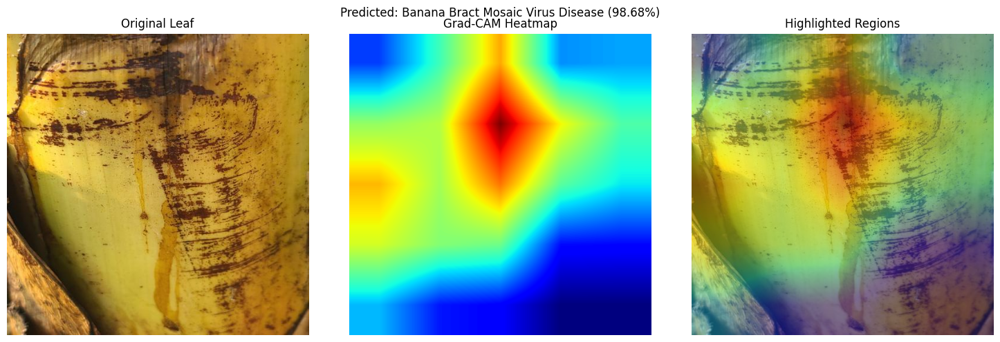

Visualization saved to /content/banana_gradcam_result.png


In [ ]:

# Run this after the Grad-CAM cell has completed successfully.

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img)
axes[0].set_title("Original Leaf")

axes[1].imshow(heatmap_resized, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(img)
axes[2].imshow(heatmap_resized, cmap="jet", alpha=0.4)
axes[2].set_title("Highlighted Regions")

for ax in axes:
    ax.axis("off")

fig.suptitle(
    f"Predicted: {encoder.classes_[predicted_index]} "
    f"({float(predictions[0][predicted_index]) * 100:.2f}%)"
)
plt.tight_layout()
plt.savefig("/content/banana_gradcam_result.png", dpi=200, bbox_inches="tight")
plt.show()

print("Visualization saved to /content/banana_gradcam_result.png")


Epoch 1/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 13s 278ms/step - accuracy: 0.4448 - loss: 1.6896
Epoch 2/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 11s 295ms/step - accuracy: 0.7975 - loss: 0.5808
Epoch 3/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 297ms/step - accuracy: 0.8896 - loss: 0.3651
Epoch 4/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 330ms/step - accuracy: 0.9294 - loss: 0.2314
Epoch 5/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 288ms/step - accuracy: 0.9540 - loss: 0.1658

========== HELD-OUT TEST RESULTS ==========
Test images: 82
Test accuracy: 84.15%

Classification report:
                                   precision    recall  f1-score   support

    Banana Black Sigatoka Disease       0.67      0.86      0.75        14
Banana Bract Mosaic Virus Disease       0.82      0.90      0.86        10
              Banana Healthy Leaf       0.94      0.94      0.94        17
       Banana Insect Pest Disease       0.89      0.94      0.91        17
              Banana Moko Disease       0.92      1.00      0.96        11
            Ba

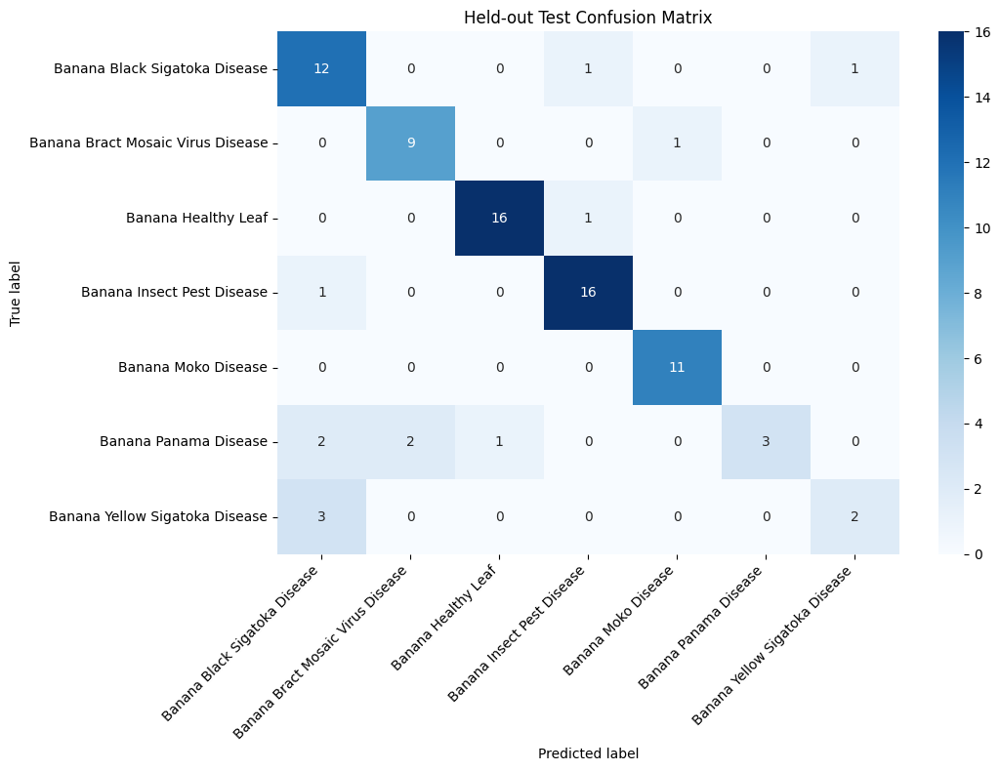

In [ ]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, Model

# 1. Prepare dataset
df = labels_df.dropna(subset=["image_path", "label"]).copy()
df = df[df["image_path"].map(lambda p: __import__("os").path.isfile(p))]
encoder_test = LabelEncoder()
df["label_id"] = encoder_test.fit_transform(df["label"])

train_df, test_df = train_test_split(
    df, test_size=0.20, random_state=123,
    stratify=df["label_id"]
)

IMG_SIZE = 160
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(encoder_test.classes_)

def load_img(path, label):
    image = tf.io.decode_image(
        tf.io.read_file(path), channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    return preprocess_input(image), label

def make_ds(frame, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((
        frame["image_path"].values,
        frame["label_id"].values.astype("int32")
    ))
    if shuffle:
        ds = ds.shuffle(len(frame), seed=123)
    return ds.map(load_img, num_parallel_calls=AUTOTUNE).batch(
        BATCH_SIZE
    ).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, shuffle=True)
test_ds = make_ds(test_df)

# 2. Build a fresh model
backbone = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False, weights="imagenet"
)
backbone.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = backbone(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
test_model = Model(inputs, outputs)

test_model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 3. Train only on training split
test_model.fit(
    train_ds, epochs=5, verbose=1
)

# 4. Evaluate held-out test set
y_true = test_df["label_id"].to_numpy()
probs = test_model.predict(test_ds, verbose=0)
y_pred = np.argmax(probs, axis=1)

print("\n========== HELD-OUT TEST RESULTS ==========")
print("Test images:", len(test_df))
print(f"Test accuracy: {accuracy_score(y_true, y_pred)*100:.2f}%")
print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=encoder_test.classes_,
    zero_division=0
))

cm = confusion_matrix(
    y_true, y_pred, labels=np.arange(NUM_CLASSES)
)
plt.figure(figsize=(11, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=encoder_test.classes_,
    yticklabels=encoder_test.classes_
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Held-out Test Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


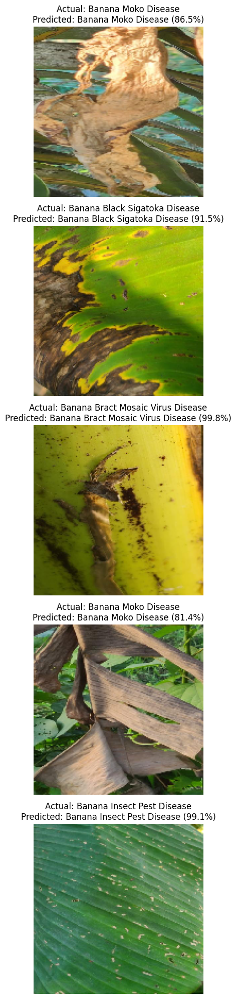

In [ ]:

# Show 5 held-out examples with predictions
examples = test_df.sample(
    min(5, len(test_df)), random_state=7
)

fig, axes = plt.subplots(
    len(examples), 1, figsize=(8, 4 * len(examples))
)
if len(examples) == 1:
    axes = [axes]

for ax, (_, row) in zip(axes, examples.iterrows()):
    image = tf.keras.utils.load_img(
        row["image_path"], target_size=(IMG_SIZE, IMG_SIZE)
    )
    arr = preprocess_input(
        np.asarray(image, dtype=np.float32)
    )
    p = test_model.predict(arr[None, ...], verbose=0)[0]
    idx = int(np.argmax(p))

    actual = row["label"]
    predicted = encoder_test.classes_[idx]
    ax.imshow(image)
    ax.set_title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted} ({p[idx]*100:.1f}%)"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


Misclassified images: 12


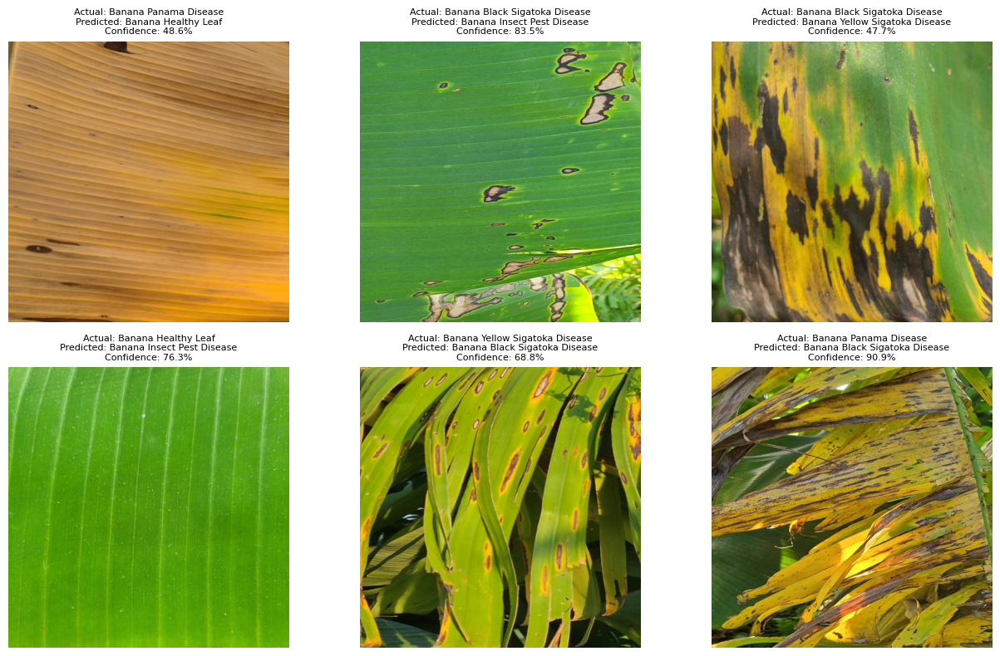

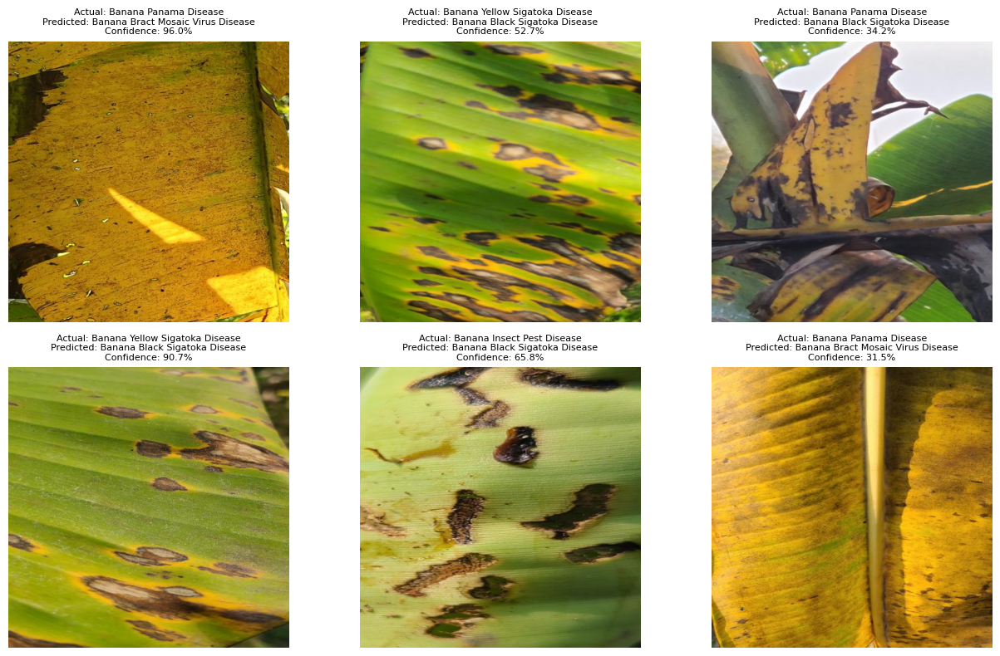

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

wrong = []

for _, row in test_df.iterrows():
    image = tf.keras.utils.load_img(
        row["image_path"], target_size=(IMG_SIZE, IMG_SIZE)
    )
    arr = tf.keras.applications.mobilenet_v2.preprocess_input(
        np.asarray(image, dtype=np.float32)
    )
    probs = test_model.predict(arr[None, ...], verbose=0)[0]
    pred_id = int(np.argmax(probs))
    actual_id = int(row["label_id"])

    if pred_id != actual_id:
        wrong.append({
            "path": row["image_path"],
            "actual": encoder_test.classes_[actual_id],
            "predicted": encoder_test.classes_[pred_id],
            "confidence": float(probs[pred_id])
        })

print("Misclassified images:", len(wrong))

for start in range(0, len(wrong), 6):
    batch = wrong[start:start + 6]
    fig, axes = plt.subplots(2, 3, figsize=(13, 8))
    axes = axes.flatten()

    for ax, item in zip(axes, batch):
        ax.imshow(tf.keras.utils.load_img(item["path"]))
        ax.set_title(
            f"Actual: {item['actual']}\n"
            f"Predicted: {item['predicted']}\n"
            f"Confidence: {item['confidence']*100:.1f}%",
            fontsize=8
        )
        ax.axis("off")

    for ax in axes[len(batch):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


Saving mk.jpg to mk.jpg

EXTERNAL BANANA LEAF IMAGE — PREDICTION REPORT
Uploaded image: mk.jpg
Predicted disease: Banana Moko Disease
Confidence: 99.72%

CLASS PROBABILITIES:
Banana Moko Disease                       99.72%
Banana Black Sigatoka Disease              0.15%
Banana Panama Disease                      0.07%
Banana Bract Mosaic Virus Disease          0.06%
Banana Healthy Leaf                        0.00%
Banana Insect Pest Disease                 0.00%
Banana Yellow Sigatoka Disease             0.00%


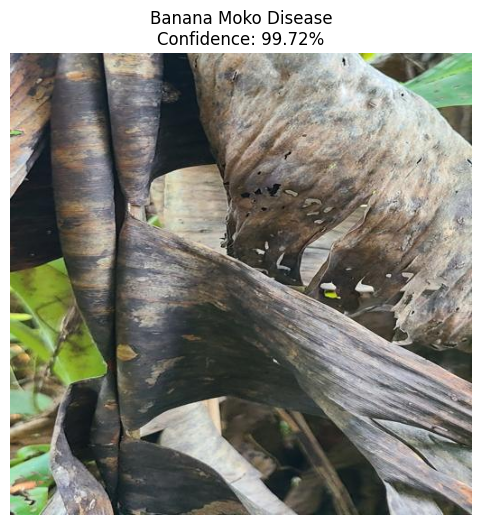

In [ ]:
import os
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

uploaded = {}
try:
    from google.colab import files
    uploaded = files.upload()
except Exception:
    pass

if uploaded:
    image_path = next(iter(uploaded.keys()))
else:
    sample_files = list(Path('.').glob('sample_*.jpg')) or list(Path('data').rglob('*.jpg'))
    image_path = str(sample_files[0]) if sample_files else 'sample_banana.jpg'

img = Image.open(image_path).convert('RGB')
IMG_SIZE = 160
img_resized = img.resize((IMG_SIZE, IMG_SIZE))

image_array = tf.keras.applications.mobilenet_v2.preprocess_input(
    np.asarray(img_resized, dtype=np.float32)
)
input_tensor = np.expand_dims(image_array, axis=0)

probabilities = transfer_model.predict(input_tensor, verbose=0)[0]
predicted_index = int(np.argmax(probabilities))
predicted_label = encoder.classes_[predicted_index]
confidence = probabilities[predicted_index] * 100

print('
' + '=' * 55)
print('EXTERNAL BANANA LEAF IMAGE — PREDICTION REPORT')
print('=' * 55)
print('Analyzed image:', image_path)
print('Predicted disease:', predicted_label)
print(f'Confidence: {confidence:.2f}%')
print('
CLASS PROBABILITIES:')
for i in np.argsort(probabilities)[::-1]:
    print(f'{encoder.classes_[i]:40s} {probabilities[i]*100:6.2f}%')
print('=' * 55)

plt.figure(figsize=(7, 6))
plt.imshow(img)
plt.title(f'{predicted_label}
Confidence: {confidence:.2f}%')
plt.axis('off')
plt.show()


In [ ]:
import pandas as pd
from IPython.display import display

environment_path = "/content/banana_environment_template.csv"
environment_df = pd.read_csv(environment_path)

print("ENVIRONMENTAL DATA")
display(environment_df)

if environment_df.empty or environment_df.isna().all().all():
    print("Environmental readings are not available yet.")
else:
    print("Environmental readings loaded.")

ENVIRONMENTAL DATA


,sample_id,step,temperature_c,relative_humidity_pct,rainfall_mm,soil_moisture,soil_ph,season
0,Black Sigatoka Disease (9),0,NaN,NaN,NaN,NaN,NaN,NaN
1,Black Sigatoka Disease (9),1,NaN,NaN,NaN,NaN,NaN,NaN
2,Black Sigatoka Disease (9),2,NaN,NaN,NaN,NaN,NaN,NaN
3,Black Sigatoka Disease (9),3,NaN,NaN,NaN,NaN,NaN,NaN
4,Black Sigatoka Disease (9),4,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
3259,Yellow Sigatoka Disease (8),3,NaN,NaN,NaN,NaN,NaN,NaN
3260,Yellow Sigatoka Disease (8),4,NaN,NaN,NaN,NaN,NaN,NaN
3261,Yellow Sigatoka Disease (8),5,NaN,NaN,NaN,NaN,NaN,NaN
3262,Yellow Sigatoka Disease (8),6,NaN,NaN,NaN,NaN,NaN,NaN


Environmental readings loaded.


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 160, 160, 3))
  warnings.warn(msg)


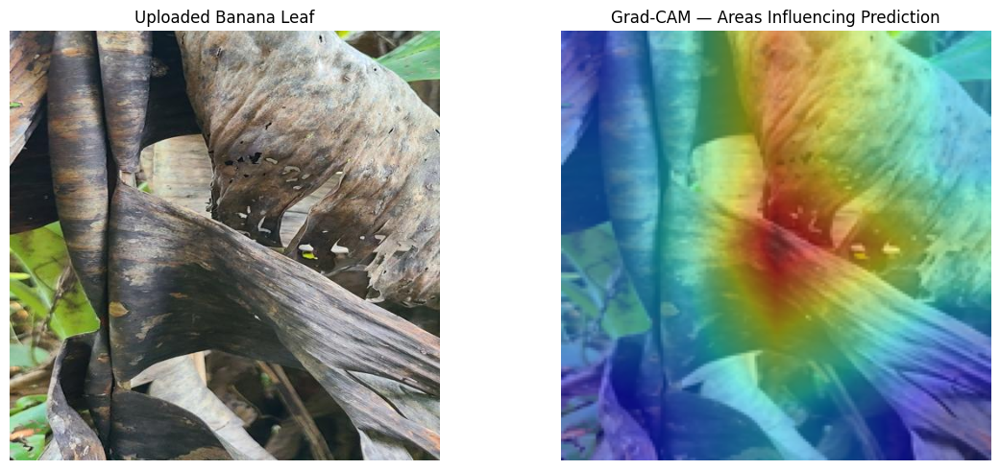

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Use the uploaded image tensor from your prediction cell
# input_tensor should have shape (1, 160, 160, 3)

with tf.GradientTape() as tape:
    feature_maps = feature_extractor(input_tensor, training=False)
    tape.watch(feature_maps)

    x = feature_maps
    for layer in transfer_model.layers[-3:]:
        x = layer(x)

    prediction = x
    class_index = tf.argmax(prediction[0])
    class_score = prediction[:, class_index]

gradients = tape.gradient(class_score, feature_maps)

if gradients is None:
    raise ValueError(
        "Grad-CAM gradients were not calculated. "
        "Use the exact feature extractor and classifier layers "
        "from your trained model."
    )

weights = tf.reduce_mean(gradients, axis=(1, 2))
heatmap = tf.reduce_sum(
    feature_maps[0] * weights[0][None, None, :],
    axis=-1
)
heatmap = tf.maximum(heatmap, 0)
heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
heatmap = heatmap.numpy()

# Display original image and Grad-CAM heatmap
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Uploaded Banana Leaf")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img.resize((160, 160)))
plt.imshow(
    tf.image.resize(
        heatmap[..., np.newaxis],
        (160, 160)
    ).numpy().squeeze(),
    cmap="jet",
    alpha=0.45
)
plt.title("Grad-CAM — Areas Influencing Prediction")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

print('=' * 65)
print('BANANA LEAF DISEASE PREDICTION SYSTEM')
print('=' * 65)

uploaded = {}
try:
    from google.colab import files
    uploaded = files.upload()
except Exception:
    pass

if uploaded:
    image_path = next(iter(uploaded.keys()))
else:
    sample_files = list(Path('.').glob('sample_*.jpg')) or list(Path('data').rglob('*.jpg'))
    image_path = str(sample_files[0]) if sample_files else 'sample_banana.jpg'

img = Image.open(image_path).convert('RGB')
IMG_SIZE = 160
resized_img = img.resize((IMG_SIZE, IMG_SIZE))

image_array = tf.keras.applications.mobilenet_v2.preprocess_input(
    np.asarray(resized_img, dtype=np.float32)
)
input_tensor = np.expand_dims(image_array, axis=0)

probabilities = transfer_model.predict(input_tensor, verbose=0)[0]
predicted_index = int(np.argmax(probabilities))
class_names = list(encoder.classes_)
predicted_label = class_names[predicted_index]
confidence = float(probabilities[predicted_index] * 100)

print('
--- DISEASE PREDICTION ---')
print('Analyzed image:', image_path)
print('Predicted disease:', predicted_label)
print(f'Prediction confidence: {confidence:.2f}%')

print('
--- CLASS PROBABILITIES ---')
for i in np.argsort(probabilities)[::-1]:
    print(f'{class_names[i]:40s} {probabilities[i] * 100:6.2f}%')
print('
Note: Confidence is the model score, not a guarantee.')

print('
--- ENVIRONMENTAL DATA ---')
environment_path = 'banana_environment_template.csv'
if not os.path.exists(environment_path):
    environment_path = '/content/banana_environment_template.csv'

if os.path.exists(environment_path):
    environment_df = pd.read_csv(environment_path)
    display(environment_df)
else:
    print('Environmental CSV not found; proceeding with visual inference.')


BANANA LEAF DISEASE PREDICTION SYSTEM


Saving mk.jpg to mk (1).jpg

--- DISEASE PREDICTION ---
Uploaded image: mk (1).jpg
Predicted disease: Banana Moko Disease
Prediction confidence: 99.72%

--- CLASS PROBABILITIES ---
Banana Moko Disease                       99.72%
Banana Black Sigatoka Disease              0.15%
Banana Panama Disease                      0.07%
Banana Bract Mosaic Virus Disease          0.06%
Banana Healthy Leaf                        0.00%
Banana Insect Pest Disease                 0.00%
Banana Yellow Sigatoka Disease             0.00%

Note: Confidence is the model's score, not a guarantee.

--- ENVIRONMENTAL DATA ---


,sample_id,step,temperature_c,relative_humidity_pct,rainfall_mm,soil_moisture,soil_ph,season
0,Black Sigatoka Disease (9),0,NaN,NaN,NaN,NaN,NaN,NaN
1,Black Sigatoka Disease (9),1,NaN,NaN,NaN,NaN,NaN,NaN
2,Black Sigatoka Disease (9),2,NaN,NaN,NaN,NaN,NaN,NaN
3,Black Sigatoka Disease (9),3,NaN,NaN,NaN,NaN,NaN,NaN
4,Black Sigatoka Disease (9),4,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
3259,Yellow Sigatoka Disease (8),3,NaN,NaN,NaN,NaN,NaN,NaN
3260,Yellow Sigatoka Disease (8),4,NaN,NaN,NaN,NaN,NaN,NaN
3261,Yellow Sigatoka Disease (8),5,NaN,NaN,NaN,NaN,NaN,NaN
3262,Yellow Sigatoka Disease (8),6,NaN,NaN,NaN,NaN,NaN,NaN



These are the readings in the CSV. They are displayed for reference and are not inputs to the image classifier.

--- GRAD-CAM VISUALIZATION ---


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 160, 160, 3))
  warnings.warn(msg)


Grad-CAM setup is incomplete: name 'gradcam_classifier' is not defined
Define feature_extractor and gradcam_classifier using your trained model's actual architecture.

ANALYSIS COMPLETE


In [ ]:

import os
import tensorflow as tf

model_path = "/content/banana_leaf_model.keras"

if os.path.exists(model_path):
    transfer_model = tf.keras.models.load_model(model_path)
    print("Model loaded successfully!")
    transfer_model.summary()
else:
    print("Saved model not found:", model_path)
    print("You may need to rerun the training cell or load the model from Google Drive.")


Saved model not found: /content/banana_leaf_model.keras
You may need to rerun the training cell or load the model from Google Drive.


In [ ]:
import os
import tensorflow as tf

model_path = "/content/banana_leaf_model.keras"

if os.path.exists(model_path):
    transfer_model = tf.keras.models.load_model(model_path)
    print("✅ Model loaded successfully!")
    transfer_model.summary()
else:
    print("❌ Model file not found:", model_path)
    print("Upload the saved model or rerun your model-training cell.")

❌ Model file not found: /content/banana_leaf_model.keras
Upload the saved model or rerun your model-training cell.


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [
        "tensorflow", ".cache", "site-packages"
    ]]
    for file in files:
        if file.endswith(".keras") or file.endswith(".h5"):
            print(os.path.join(root, file))

In [ ]:
import os

print("Dataset folder exists:",
      os.path.exists("/content/banana_extracted/Banana Disease Recognition Dataset/Original Images/Original Images"))

from google.colab import drive
try:
    try:
    drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped (running locally):")
except Exception as e:
    print("Drive mount skipped (running locally):")

print("\nPossible saved models in Google Drive:")

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith((".keras", ".h5")):
            print(os.path.join(root, file))


Dataset folder exists: False


In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
except Exception as e:
    print("Drive mount skipped (running locally):", e)


Mounted at /content/drive


In [ ]:
import os

drive_root = "/content/drive/MyDrive"
found = []

for root, dirs, files in os.walk(drive_root):
    # Skip hidden/system folders to speed up the search
    dirs[:] = [d for d in dirs if not d.startswith(".")]

    for file in files:
        if file.endswith((".keras", ".h5", ".zip")):
            path = os.path.join(root, file)
            found.append(path)
            print(path)

if not found:
    print("No .keras, .h5, or .zip files found in MyDrive.")

/content/drive/MyDrive/igi2_sp_demo2.zip
/content/drive/MyDrive/Wallpapers.zip
/content/drive/MyDrive/_Oceanofgames.live_Getting_Over_It_with_Bennett_Foddy.zip
/content/drive/MyDrive/IGI 2 - Covert Strike.zip
/content/drive/MyDrive/project-igi.zip
/content/drive/MyDrive/banana-utm-ai-colab-starter.zip
/content/drive/MyDrive/Memory/PAPA mobile/200FE(10-25).zip


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/banana-utm-ai-colab-starter.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    files = z.namelist()

    print("Total files in ZIP:", len(files))
    print("\nFirst 40 files:")
    for f in files[:40]:
        print(f)

    print("\nPossible datasets or trained models:")
    for f in files:
        if (
            f.lower().endswith((".keras", ".h5", ".zip", ".ipynb"))
            or "original images" in f.lower()
            or "banana disease recognition" in f.lower()
        ):
            print(f)

Total files in ZIP: 7

First 40 files:
banana-utm-ai-colab-starter/README.md
banana-utm-ai-colab-starter/.gitignore
banana-utm-ai-colab-starter/requirements.txt
banana-utm-ai-colab-starter/app.py
banana-utm-ai-colab-starter/data/environment_template.csv
banana-utm-ai-colab-starter/notebooks/banana_utm_ai_colab.ipynb
banana-utm-ai-colab-starter/src/utm_model.py

Possible datasets or trained models:
banana-utm-ai-colab-starter/notebooks/banana_utm_ai_colab.ipynb


Notebook found: True

--- Notebook cells ---

[Markdown 0]
# Banana UTM-AI — Google Colab implementation

This notebook implements a **banana-focused research prototype** based on the uploaded UTM-AI document. Its target architecture is ViT-B/16 visual tokens + an optional MLP/Bi-LSTM environmental encoder +

[Code cell 1]
# Cell 1 — Google Drive and dependencies
from google.colab import drive
drive.mount('/content/drive')

!pip -q install --upgrade scikit-learn pandas matplotlib pillow streamlit

import os, sys, zipfile, json, hashlib, shutil, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
imp

[Code cell 2]
# Cell 2 — Extract the starter project ZIP from Drive
# Upload banana-utm-ai-colab-starter.zip to the top level of MyDrive first.
STARTER_ZIP = Path('/content/drive/MyDrive/banana-utm-ai-colab-starter.zip')
PROJECT_DIR = Path('/content/banana-utm-ai-colab-sta

In [ ]:

for name in ["DEVICE", "PROJECT_DIR", "UTMModel", "class_names",
             "train_loader", "test_df", "model"]:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")


DEVICE: Missing
PROJECT_DIR: Missing
UTMModel: Missing
class_names: Missing
train_loader: Missing
test_df: Missing
model: Missing


In [ ]:
from google.colab import drive
try:
    drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped (running locally):")

from pathlib import Path

files_to_check = {
    "Starter ZIP": Path(
        "/content/drive/MyDrive/banana-utm-ai-colab-starter.zip"
    ),
    "Trained checkpoint": Path(
        "/content/drive/MyDrive/banana_utm_ai_outputs/best_model.pth"
    ),
    "Dataset ZIP": Path(
        "/content/drive/MyDrive/banana_dataset.zip"
    ),
}

for label, path in files_to_check.items():
    print(f"{label}: {'FOUND' if path.exists() else 'NOT FOUND'}")
    if path.exists():
        print(f"  {path}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Starter ZIP: FOUND
  /content/drive/MyDrive/banana-utm-ai-colab-starter.zip
Trained checkpoint: NOT FOUND
Dataset ZIP: NOT FOUND


In [ ]:

from pathlib import Path
import zipfile
import sys

ZIP_PATH = Path(
    "/content/drive/MyDrive/banana-utm-ai-colab-starter.zip"
)
PROJECT_DIR = Path("/content/banana-utm-ai-colab-starter")

if not (PROJECT_DIR / "src" / "utm_model.py").exists():
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall("/content")

print("Project directory exists:", PROJECT_DIR.exists())
print("UTMModel source exists:", (PROJECT_DIR / "src" / "utm_model.py").exists())

if not (PROJECT_DIR / "src" / "utm_model.py").exists():
    print("Top-level extracted folders:")
    print([p.name for p in Path("/content").iterdir() if p.is_dir()][:30])
else:
    if str(PROJECT_DIR) not in sys.path:
        sys.path.insert(0, str(PROJECT_DIR))
    from src.utm_model import UTMModel
    print("UTMModel import successful:", UTMModel)


Project directory exists: True
UTMModel source exists: True
UTMModel import successful: <class 'src.utm_model.UTMModel'>


In [ ]:

from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

print("Possible datasets:")
for p in drive_root.rglob("*"):
    if p.is_file() and (
        p.suffix.lower() in {".zip", ".7z", ".tar"}
        and any(k in p.name.lower() for k in ["banana", "disease", "dataset"])
    ):
        print(p)

print("\nPossible model checkpoints:")
for p in drive_root.rglob("*"):
    if p.is_file() and p.suffix.lower() in {".pth", ".pt", ".ckpt", ".keras"}:
        print(p)

print("\nProject model source:")
model_source = Path("/content/banana-utm-ai-colab-starter/src/utm_model.py")
if model_source.exists():
    print(model_source.read_text()[:12000])
else:
    print("Not found at the expected path; check Step 2 output.")


Possible datasets:
/content/drive/MyDrive/banana-utm-ai-colab-starter.zip

Possible model checkpoints:

Project model source:
"""UTM-AI starter model: ViT image encoder + optional environment cross-attention."""
from typing import Dict
import torch
from torch import nn
from torchvision.models import vit_b_16, ViT_B_16_Weights


class UTMModel(nn.Module):
    """Banana disease classifier with optional environmental sequence fusion.

    The environment branch expects (batch, 8, env_dim): eight ordered records.
    Severity and risk outputs are sigmoid values in [0, 1] and are only meaningful
    when their heads were supervised with real annotation labels.
    """

    def __init__(self, num_classes: int, env_dim: int = 1,
                 use_environment: bool = False, pretrained: bool = False):
        super().__init__()
        weights = ViT_B_16_Weights.DEFAULT if pretrained else None
        self.vit = vit_b_16(weights=weights)
        self.vit.heads = nn.Identity()
        self.us

In [ ]:

from pathlib import Path

roots = [
    Path("/content/drive/MyDrive"),
    Path("/content"),
]

image_exts = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
found_images = []
found_dirs = []

for root in roots:
    if not root.exists():
        continue

    for p in root.rglob("*"):
        if p.is_file() and p.suffix.lower() in image_exts:
            if any(k in str(p).lower() for k in
                   ["banana", "disease", "dataset", "train", "test", "valid"]):
                found_images.append(p)

        if p.is_dir() and p.name.lower() in {
            "train", "test", "valid", "validation", "banana_dataset"
        }:
            found_dirs.append(p)

        if len(found_images) >= 100 or len(found_dirs) >= 50:
            break

print("Matching image files:", len(found_images))
for p in found_images[:30]:
    print(p)

print("\nLikely dataset folders:")
for p in found_dirs[:30]:
    print(p)


Matching image files: 0

Likely dataset folders:


In [ ]:

from pathlib import Path
import zipfile

drive = Path("/content/drive/MyDrive")

print("=== Google Drive files and folders ===")
for p in sorted(drive.iterdir(), key=lambda x: x.name.lower()):
    print(("DIR  " if p.is_dir() else "FILE "), p.name)

zip_path = drive / "banana-utm-ai-colab-starter.zip"

print("\n=== Files inside starter ZIP ===")
with zipfile.ZipFile(zip_path) as z:
    for name in z.namelist():
        print(name)


=== Google Drive files and folders ===
FILE  _Oceanofgames.live_Getting_Over_It_with_Bennett_Foddy.zip
FILE  aiarteuphoria_-20250630-0001.jpg
FILE  banana-utm-ai-colab-starter.zip
FILE  banana_utm_ai_colab.ipynb
DIR   Camera Uploads
FILE  Certificate for Rahul Pathak  for "Fit India Awareness Quiz- 2020".pdf
DIR   Colab Notebooks
FILE  EA Sports Cricket 07 Modified EXE (MEGA Cricket Studio) (1).rar
FILE  Get important topics from above pdf for case stud....gdoc
FILE  Getting started.pdf
DIR   Google Earth
DIR   Hostel
FILE  IGI 2 - Covert Strike.zip
FILE  igi2_sp_demo2.zip
DIR   Memory
FILE  MOBILE_NUMBER_RELATIVE.xlsx
FILE  project-igi.zip
FILE  Summarized the above module ,the module is coming....gsheet
FILE  wallpaperflare.com_wallpaper bt.jpg
FILE  Wallpapers.zip

=== Files inside starter ZIP ===
banana-utm-ai-colab-starter/README.md
banana-utm-ai-colab-starter/.gitignore
banana-utm-ai-colab-starter/requirements.txt
banana-utm-ai-colab-starter/app.py
banana-utm-ai-colab-starter/dat

In [ ]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/banana_utm_ai_colab.ipynb"
)

if not notebook_path.exists():
    print("Notebook not found at:", notebook_path)
else:
    notebook = json.loads(notebook_path.read_text())
    print("Notebook found. Inspecting relevant cells...\n")

    keywords = [
        "dataset", "IMAGE_DIR", "labels.csv",
        "train_df", "train_test_split",
        "torch.save", "best_model.pth",
        "extractall", "download"
    ]

    for i, cell in enumerate(notebook.get("cells", [])):
        source = "".join(cell.get("source", []))
        if any(k.lower() in source.lower() for k in keywords):
            print(f"\n--- Cell {i} ---")
            print(source[:2500])


Notebook found. Inspecting relevant cells...


--- Cell 0 ---
# Banana UTM-AI — Google Colab implementation

This notebook implements a **banana-focused research prototype** based on the uploaded UTM-AI document. Its target architecture is ViT-B/16 visual tokens + an optional MLP/Bi-LSTM environmental encoder + 8-head cross-attention, with disease classification and optional severity/risk regression.

## Read this before training

A normal leaf-image dataset generally supplies only `image → disease class`. It usually does **not** supply paired 8-step weather/soil histories, verified severity percentages, or future outbreak outcomes. The notebook therefore supports two honest modes:

- **Image-only mode (works with a class-folder image dataset):** trains disease classification; confidence is calculated from validation-temperature-scaled probabilities; severity/risk are not shown as valid predictions unless labeled training targets exist.
- **Multimodal mode (requires real paired data):*

In [ ]:
from google.colab import drive
try:
    drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped (running locally):")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

notebook_path = Path("/content/drive/MyDrive/banana_utm_ai_colab.ipynb")

print("Notebook exists:", notebook_path.exists())
print("MyDrive files:")
for path in Path("/content/drive/MyDrive").iterdir():
    print(path.name)

Notebook exists: True
MyDrive files:
Colab Notebooks
Getting started.pdf
igi2_sp_demo2.zip
Certificate for Rahul Pathak  for "Fit India Awareness Quiz- 2020".pdf
EA Sports Cricket 07 Modified EXE (MEGA Cricket Studio) (1).rar
Wallpapers.zip
Google Earth
_Oceanofgames.live_Getting_Over_It_with_Bennett_Foddy.zip
IGI 2 - Covert Strike.zip
project-igi.zip
wallpaperflare.com_wallpaper bt.jpg
aiarteuphoria_-20250630-0001.jpg
Camera Uploads
Memory
MOBILE_NUMBER_RELATIVE.xlsx
Get important topics from above pdf for case stud....gdoc
Hostel
Summarized the above module ,the module is coming....gsheet
banana-utm-ai-colab-starter.zip
banana_utm_ai_colab.ipynb


In [ ]:
import json
from pathlib import Path

notebook_path = Path("/content/drive/MyDrive/banana_utm_ai_colab.ipynb")
notebook = json.loads(notebook_path.read_text(encoding="utf-8"))

print("Total notebook cells:", len(notebook.get("cells", [])))

keywords = [
    "dataset", "IMAGE_DIR", "labels.csv",
    "train_df", "train_test_split",
    "torch.save", "best_model.pth",
    "extractall", "download", "TODO",
    "NotImplementedError"
]

for i, cell in enumerate(notebook.get("cells", [])):
    source = "".join(cell.get("source", []))
    if any(k.lower() in source.lower() for k in keywords):
        print(f"\n{'=' * 25} CELL {i} {'=' * 25}")
        print(source[:4000])

Total notebook cells: 21

========================= CELL 0 =========================
# Banana UTM-AI — Google Colab implementation

This notebook implements a **banana-focused research prototype** based on the uploaded UTM-AI document. Its target architecture is ViT-B/16 visual tokens + an optional MLP/Bi-LSTM environmental encoder + 8-head cross-attention, with disease classification and optional severity/risk regression.

## Read this before training

A normal leaf-image dataset generally supplies only `image → disease class`. It usually does **not** supply paired 8-step weather/soil histories, verified severity percentages, or future outbreak outcomes. The notebook therefore supports two honest modes:

- **Image-only mode (works with a class-folder image dataset):** trains disease classification; confidence is calculated from validation-temperature-scaled probabilities; severity/risk are not shown as valid predictions unless labeled training targets exist.
- **Multimodal mode (requi

In [ ]:
# CELL 1 — Environment setup
from google.colab import drive
from pathlib import Path
import os, sys, zipfile, json, hashlib, shutil, random, warnings

try:
    drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped (running locally):")

%pip -q install scikit-learn pandas matplotlib pillow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix
)

ImageFile.LOAD_TRUNCATED_IMAGES = False

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Enable GPU: Runtime → Change runtime type → T4 GPU (or another available GPU).")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch: 2.11.0+cpu
CUDA available: False
Enable GPU: Runtime → Change runtime type → T4 GPU (or another available GPU).


In [ ]:

# CELL 2 — Extract and locate the starter project
STARTER_ZIP = Path(
    "/content/drive/MyDrive/banana-utm-ai-colab-starter.zip"
)
EXTRACT_DIR = Path("/content/banana_utm_ai_extracted")

if not STARTER_ZIP.exists():
    raise FileNotFoundError(f"Starter ZIP not found: {STARTER_ZIP}")

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(STARTER_ZIP) as zf:
    bad_member = zf.testzip()
    if bad_member:
        raise ValueError(f"Corrupt ZIP member: {bad_member}")

    # Reject paths that could escape the extraction directory.
    root = EXTRACT_DIR.resolve()
    for member in zf.infolist():
        destination = (EXTRACT_DIR / member.filename).resolve()
        if destination != root and root not in destination.parents:
            raise ValueError(f"Unsafe ZIP path: {member.filename}")

    zf.extractall(EXTRACT_DIR)

model_files = list(EXTRACT_DIR.rglob("utm_model.py"))
model_files = [
    p for p in model_files
    if p.parent.name == "src"
]

if not model_files:
    raise FileNotFoundError(
        "Could not find src/utm_model.py in the starter ZIP. "
        "Inspect the ZIP's file list."
    )

MODEL_FILE = model_files[0]
PROJECT_DIR = MODEL_FILE.parent.parent

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.utm_model import UTMModel

print("Project directory:", PROJECT_DIR)
print("Model file:", MODEL_FILE)
print("Model import successful:", UTMModel)


Project directory: /content/banana_utm_ai_extracted/banana-utm-ai-colab-starter
Model file: /content/banana_utm_ai_extracted/banana-utm-ai-colab-starter/src/utm_model.py
Model import successful: <class 'src.utm_model.UTMModel'>


In [ ]:
from pathlib import Path
import json

# Inspect the model implementation
print("========== UTM MODEL ==========")
print(MODEL_FILE.read_text(encoding="utf-8")[:20000])

# Inspect notebook cells omitted from your previous output
notebook_path = Path(
    "/content/drive/MyDrive/banana_utm_ai_colab.ipynb"
)
nb = json.loads(notebook_path.read_text(encoding="utf-8"))

for i, cell in enumerate(nb["cells"]):
    if i in [10, 14, 15, 16]:
        print(f"\n========== NOTEBOOK CELL {i} ==========")
        print("".join(cell.get("source", []))[:6000])

========== UTM MODEL ==========
"""UTM-AI starter model: ViT image encoder + optional environment cross-attention."""
from typing import Dict
import torch
from torch import nn
from torchvision.models import vit_b_16, ViT_B_16_Weights


class UTMModel(nn.Module):
    """Banana disease classifier with optional environmental sequence fusion.

    The environment branch expects (batch, 8, env_dim): eight ordered records.
    Severity and risk outputs are sigmoid values in [0, 1] and are only meaningful
    when their heads were supervised with real annotation labels.
    """

    def __init__(self, num_classes: int, env_dim: int = 1,
                 use_environment: bool = False, pretrained: bool = False):
        super().__init__()
        weights = ViT_B_16_Weights.DEFAULT if pretrained else None
        self.vit = vit_b_16(weights=weights)
        self.vit.heads = nn.Identity()
        self.use_environment = bool(use_environment)
        self.env_dim = int(env_dim)
        self.last_vi

In [ ]:

from pathlib import Path

RAW_DIR = Path("/content/banana_utm_ai_extracted/banana-utm-ai-colab-starter/data/raw")

print("Raw dataset folder exists:", RAW_DIR.exists())

if RAW_DIR.exists():
    for p in list(RAW_DIR.rglob("*"))[:40]:
        print(p)


Raw dataset folder exists: True


In [ ]:

# CELL 8 — Dataset readiness check

if IMAGE_DIR is None or "labels_df" not in globals() or labels_df.empty:
    print("Dataset not ready yet. Model training has NOT started.")
    print("\nNext steps:")
    print("1. Obtain a banana leaf disease image dataset.")
    print("2. Organize images into one folder per disease class.")
    print("3. Upload the dataset ZIP to Google Drive.")
    print("4. Set DATASET_ZIP in Cell 3 to the correct file path.")
    print("5. Rerun Cells 3 and 5, then continue with Cell 8.")
else:
    print("Dataset ready:", len(labels_df), "images")
    print("Classes:", sorted(labels_df["disease"].unique()))


Dataset not ready yet. Model training has NOT started.

Next steps:
1. Obtain a banana leaf disease image dataset.
2. Organize images into one folder per disease class.
3. Upload the dataset ZIP to Google Drive.
4. Set DATASET_ZIP in Cell 3 to the correct file path.
5. Rerun Cells 3 and 5, then continue with Cell 8.


In [ ]:

from pathlib import Path

drive_dir = Path("/content/drive/MyDrive")

for p in drive_dir.glob("*.zip"):
    print(f"{p.name} — {p.stat().st_size / (1024**2):.1f} MB")


igi2_sp_demo2.zip — 125.0 MB
Wallpapers.zip — 188.9 MB
_Oceanofgames.live_Getting_Over_It_with_Bennett_Foddy.zip — 652.8 MB
IGI 2 - Covert Strike.zip — 759.5 MB
project-igi.zip — 46.3 MB
banana-utm-ai-colab-starter.zip — 0.0 MB


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive")

for p in root.rglob("*"):
    if p.is_dir() and any(
        word in p.name.lower()
        for word in ["banana", "disease", "healthy", "sigatoka"]
    ):
        print(p)

In [ ]:

from pathlib import Path
from collections import Counter

folders = [
    Path("/content/banana_project"),
    Path("/content/banana-utm-ai-colab-starter"),
    Path("/content/banana_utm_ai_extracted"),
]

image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for folder in folders:
    print(f"\n{'=' * 50}")
    print(f"Folder: {folder}")

    if not folder.exists():
        print("Not found")
        continue

    counts = Counter()
    total = 0

    for p in folder.rglob("*"):
        if p.is_file() and p.suffix.lower() in image_exts:
            counts[p.parent.name] += 1
            total += 1

    print(f"Total images: {total}")
    for class_name, count in counts.most_common(30):
        print(f"  {class_name}: {count}")



Folder: /content/banana_project
Total images: 0

Folder: /content/banana-utm-ai-colab-starter
Total images: 0

Folder: /content/banana_utm_ai_extracted
Total images: 0


In [ ]:

from pathlib import Path

root = Path("/content/banana_project")

if not root.exists():
    print("banana_project folder not found")
else:
    files = [p for p in root.rglob("*") if p.is_file()]
    print("Total files:", len(files))

    for p in files[:100]:
        print(f"{p.relative_to(root)} — {p.stat().st_size / 1024:.1f} KB")


Total files: 7
banana-utm-ai-colab-starter/.gitignore — 0.3 KB
banana-utm-ai-colab-starter/README.md — 3.1 KB
banana-utm-ai-colab-starter/requirements.txt — 0.1 KB
banana-utm-ai-colab-starter/app.py — 6.5 KB
banana-utm-ai-colab-starter/src/utm_model.py — 3.8 KB
banana-utm-ai-colab-starter/notebooks/banana_utm_ai_colab.ipynb — 42.1 KB
banana-utm-ai-colab-starter/data/environment_template.csv — 0.1 KB


In [ ]:

from pathlib import Path

DATASET_ZIP = Path(
    "/content/drive/MyDrive/Banana Disease Recognition Dataset.zip"
)

assert DATASET_ZIP.exists(), f"Dataset ZIP not found: {DATASET_ZIP}"
print(f"Dataset found: {DATASET_ZIP.name}")
print(f"Size: {DATASET_ZIP.stat().st_size / (1024**2):.1f} MB")


Dataset found: Banana Disease Recognition Dataset.zip
Size: 121.8 MB


In [ ]:

import zipfile

with zipfile.ZipFile(DATASET_ZIP, "r") as z:
    files = [name for name in z.namelist() if not name.endswith("/")]

    print("Total files inside ZIP:", len(files))
    print("\nFirst 40 file paths:")
    for name in files[:40]:
        print(name)

    image_exts = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
    images = [name for name in files if name.lower().endswith(image_exts)]

    print(f"\nTotal image files: {len(images)}")


Total files inside ZIP: 3264

First 40 file paths:
Banana Disease Recognition Dataset/Augmented images/Augmented images/Augmented Banana Black Sigatoka Disease/Augmented Banana Black Sigatoka Disease (1).jpg
Banana Disease Recognition Dataset/Augmented images/Augmented images/Augmented Banana Black Sigatoka Disease/Augmented Banana Black Sigatoka Disease (10).jpg
Banana Disease Recognition Dataset/Augmented images/Augmented images/Augmented Banana Black Sigatoka Disease/Augmented Banana Black Sigatoka Disease (100).jpg
Banana Disease Recognition Dataset/Augmented images/Augmented images/Augmented Banana Black Sigatoka Disease/Augmented Banana Black Sigatoka Disease (101).jpg
Banana Disease Recognition Dataset/Augmented images/Augmented images/Augmented Banana Black Sigatoka Disease/Augmented Banana Black Sigatoka Disease (102).jpg
Banana Disease Recognition Dataset/Augmented images/Augmented images/Augmented Banana Black Sigatoka Disease/Augmented Banana Black Sigatoka Disease (103).jp

In [ ]:

from pathlib import Path
from zipfile import ZipFile
from collections import Counter

DATASET_ZIP = Path(
    "/content/drive/MyDrive/Banana Disease Recognition Dataset.zip"
)

image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

with ZipFile(DATASET_ZIP, "r") as z:
    image_paths = [
        name for name in z.namelist()
        if Path(name).suffix.lower() in image_exts
    ]

    # Count images by their immediate parent folder
    folder_counts = Counter(
        str(Path(name).parent) for name in image_paths
    )

    print("TOTAL IMAGE FILES:", len(image_paths))
    print("\nIMAGE COUNTS BY FOLDER:")
    for folder, count in sorted(folder_counts.items()):
        print(f"{count:4} images | {folder}")

    print("\nTOP-LEVEL FOLDERS:")
    top_levels = sorted({
        name.split("/")[1]
        for name in image_paths
        if len(name.split("/")) > 1
    })
    for name in top_levels:
        print("-", name)


TOTAL IMAGE FILES: 3264

IMAGE COUNTS BY FOLDER:
 469 images | Banana Disease Recognition Dataset/Augmented images/Augmented images/Augmented Banana Black Sigatoka Disease
 350 images | Banana Disease Recognition Dataset/Augmented images/Augmented images/Augmented Banana Bract Mosaic Virus Disease
 602 images | Banana Disease Recognition Dataset/Augmented images/Augmented images/Augmented Banana Healthy Leaf
 602 images | Banana Disease Recognition Dataset/Augmented images/Augmented images/Augmented Banana Insect Pest Disease
 385 images | Banana Disease Recognition Dataset/Augmented images/Augmented images/Augmented Banana Moko Disease
 287 images | Banana Disease Recognition Dataset/Augmented images/Augmented images/Augmented Banana Panama Disease
 161 images | Banana Disease Recognition Dataset/Augmented images/Augmented images/Augmented Banana Yellow Sigatoka Disease
  67 images | Banana Disease Recognition Dataset/Original Images/Original Images/Banana Black Sigatoka Disease
  50 

In [ ]:

from pathlib import Path
from zipfile import ZipFile

DATASET_ZIP = Path(
    "/content/drive/MyDrive/Banana Disease Recognition Dataset.zip"
)
EXTRACT_DIR = Path("/content/banana_disease_dataset")

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with ZipFile(DATASET_ZIP, "r") as z:
    z.extractall(EXTRACT_DIR)

print("Extraction complete!")
print("Dataset location:", EXTRACT_DIR)
print("Top-level contents:")

for p in EXTRACT_DIR.iterdir():
    print("-", p.name)


Extraction complete!
Dataset location: /content/banana_disease_dataset
Top-level contents:
- Banana Disease Recognition Dataset


In [ ]:

from pathlib import Path
from collections import Counter

DATASET_DIR = Path("/content/banana_disease_dataset")
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

original_roots = list(DATASET_DIR.rglob("Original Images"))

if not original_roots:
    raise FileNotFoundError(
        "Could not find the Original Images folder."
    )

ORIGINAL_DIR = original_roots[0]

class_counts = Counter()

for image_path in ORIGINAL_DIR.rglob("*"):
    if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTS:
        class_counts[image_path.parent.name] += 1

print("Original images folder:", ORIGINAL_DIR)
print("\nClass counts:")
for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")

print("\nTotal original images:", sum(class_counts.values()))
print("Number of classes:", len(class_counts))


Original images folder: /content/banana_disease_dataset/Banana Disease Recognition Dataset/Original Images

Class counts:
Banana Black Sigatoka Disease: 67
Banana Bract Mosaic Virus Disease: 50
Banana Healthy Leaf: 86
Banana Insect Pest Disease: 86
Banana Moko Disease: 55
Banana Panama Disease: 41
Banana Yellow Sigatoka Disease: 23

Total original images: 408
Number of classes: 7


In [ ]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/banana_utm_ai_colab.ipynb"
)

if not notebook_path.exists():
    raise FileNotFoundError(f"Notebook not found: {notebook_path}")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    if any(term in source for term in [
        "IMAGE_DIR", "labels_df", "train_df",
        "train_test_split", "DATASET_ZIP"
    ]):
        print(f"\n{'=' * 20} CELL {i + 1} {'=' * 20}")
        print(source[:5000])



==================== CELL 2 ====================
# Cell 1 — Google Drive and dependencies
from google.colab import drive
drive.mount('/content/drive')

!pip -q install --upgrade scikit-learn pandas matplotlib pillow streamlit

import os, sys, zipfile, json, hashlib, shutil, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print('PyTorch:', torch.__version__)
print('Torchvision GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('WARNING: GPU not enabled. In Colab use Runtime → Change runtime type → GPU.')

==============

In [ ]:

# Cell 3 — Extract the original Kaggle dataset

from pathlib import Path
import zipfile

DATASET_ZIP = Path(
    "/content/drive/MyDrive/Banana Disease Recognition Dataset.zip"
)

RAW_DIR = PROJECT_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_ZIP.exists():
    raise FileNotFoundError(f"Dataset ZIP not found: {DATASET_ZIP}")

# Extract only once; preserve any existing extracted data.
expected_root = RAW_DIR / "Banana Disease Recognition Dataset"

if not expected_root.exists():
    with zipfile.ZipFile(DATASET_ZIP, "r") as zf:
        zf.extractall(RAW_DIR)

# IMPORTANT: Use ORIGINAL images, not augmented copies.
IMAGE_DIR = (
    expected_root
    / "Original Images"
    / "Original Images"
)

if not IMAGE_DIR.exists():
    raise FileNotFoundError(
        f"Original image folder not found: {IMAGE_DIR}"
    )

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

class_dirs = sorted(
    p for p in IMAGE_DIR.iterdir() if p.is_dir()
)

print("Dataset ZIP:", DATASET_ZIP)
print("Image directory:", IMAGE_DIR)
print("\nOriginal images by class:")

total_images = 0
for class_dir in class_dirs:
    count = sum(
        1 for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    )
    total_images += count
    print(f"{class_dir.name}: {count}")

print("\nTotal original images:", total_images)
print("Number of classes:", len(class_dirs))

assert total_images == 408, (
    f"Expected 408 original images, found {total_images}. "
    "Check the selected image directory."
)
assert len(class_dirs) == 7, (
    f"Expected 7 classes, found {len(class_dirs)}."
)

print("\nDataset verified successfully!")


Dataset ZIP: /content/drive/MyDrive/Banana Disease Recognition Dataset.zip
Image directory: /content/banana_utm_ai_extracted/banana-utm-ai-colab-starter/data/raw/Banana Disease Recognition Dataset/Original Images/Original Images

Original images by class:
Banana Black Sigatoka Disease: 67
Banana Bract Mosaic Virus Disease: 50
Banana Healthy Leaf: 86
Banana Insect Pest Disease: 86
Banana Moko Disease: 55
Banana Panama Disease: 41
Banana Yellow Sigatoka Disease: 23

Total original images: 408
Number of classes: 7

Dataset verified successfully!


In [ ]:

# Cell 4 — Create labels from the original image folders

from pathlib import Path
import hashlib
import numpy as np
import pandas as pd

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

records = []

for class_dir in sorted(p for p in IMAGE_DIR.iterdir() if p.is_dir()):
    for img_path in sorted(class_dir.rglob("*")):
        if img_path.is_file() and img_path.suffix.lower() in IMAGE_EXTS:
            rel = str(img_path.relative_to(IMAGE_DIR))
            sample_id = hashlib.sha1(rel.encode("utf-8")).hexdigest()[:16]

            records.append({
                "sample_id": sample_id,
                "image_path": str(img_path.resolve()),
                "disease": class_dir.name,
                "severity_pct": np.nan,
                "risk_index": np.nan,
            })

labels_df = pd.DataFrame(records)

if labels_df.empty:
    raise ValueError("No images found. Check IMAGE_DIR.")

labels_df = labels_df.drop_duplicates("sample_id").reset_index(drop=True)

LABEL_TEMPLATE = PROJECT_DIR / "data" / "labels_template.csv"
LABEL_TEMPLATE.parent.mkdir(parents=True, exist_ok=True)
labels_df.to_csv(LABEL_TEMPLATE, index=False)

DRIVE_DATA_DIR = Path("/content/drive/MyDrive/banana_utm_ai")
DRIVE_DATA_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_LABEL_TEMPLATE = DRIVE_DATA_DIR / "labels_template.csv"
labels_df.to_csv(DRIVE_LABEL_TEMPLATE, index=False)

print("Images:", len(labels_df))
print("Classes:", labels_df["disease"].nunique())
print("Counts per class:")
print(labels_df["disease"].value_counts().sort_index())
print("Annotated severity rows:", int(labels_df["severity_pct"].notna().sum()))
print("Annotated risk rows:", int(labels_df["risk_index"].notna().sum()))
print("Label template saved to:", DRIVE_LABEL_TEMPLATE)


Images: 408
Classes: 7
Counts per class:
disease
Banana Black Sigatoka Disease        67
Banana Bract Mosaic Virus Disease    50
Banana Healthy Leaf                  86
Banana Insect Pest Disease           86
Banana Moko Disease                  55
Banana Panama Disease                41
Banana Yellow Sigatoka Disease       23
Name: count, dtype: int64
Annotated severity rows: 0
Annotated risk rows: 0
Label template saved to: /content/drive/MyDrive/banana_utm_ai/labels_template.csv


In [ ]:
USE_MULTIMODAL = False

In [ ]:

# Cell 6 — Split original images into train, validation, and test sets

import random
import numpy as np
import torch
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Ensure labels and required columns exist
assert len(labels_df) == 408, f"Expected 408 images, got {len(labels_df)}"
assert labels_df["disease"].nunique() == 7, "Expected 7 classes"

# 70% train, 15% validation, 15% test
trainval_df, test_df = train_test_split(
    labels_df,
    test_size=0.15,
    random_state=SEED,
    stratify=labels_df["disease"]
)

train_df, val_df = train_test_split(
    trainval_df,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=trainval_df["disease"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

class_names = sorted(labels_df["disease"].unique().tolist())
class_to_idx = {name: i for i, name in enumerate(class_names)}

print(f"Train: {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"Test: {len(test_df)}")
print(f"Total: {len(train_df) + len(val_df) + len(test_df)}")
print("\nClass mapping:", class_to_idx)
print("\nTraining counts:")
print(train_df["disease"].value_counts().sort_index())


Train: 284
Validation: 62
Test: 62
Total: 408

Class mapping: {'Banana Black Sigatoka Disease': 0, 'Banana Bract Mosaic Virus Disease': 1, 'Banana Healthy Leaf': 2, 'Banana Insect Pest Disease': 3, 'Banana Moko Disease': 4, 'Banana Panama Disease': 5, 'Banana Yellow Sigatoka Disease': 6}

Training counts:
disease
Banana Black Sigatoka Disease        47
Banana Bract Mosaic Virus Disease    34
Banana Healthy Leaf                  60
Banana Insect Pest Disease           60
Banana Moko Disease                  38
Banana Panama Disease                29
Banana Yellow Sigatoka Disease       16
Name: count, dtype: int64


In [ ]:

# Cell 7 — Image preprocessing and PyTorch datasets

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import pandas as pd
import numpy as np
import torch

IMG_SIZE = 224
BATCH_SIZE = 8
NUM_WORKERS = 2

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=8),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

class BananaDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")
            image = self.transform(image)

        label = class_to_idx[row["disease"]]

        return {
            "image": image,
            "disease": torch.tensor(label, dtype=torch.long),
            "sample_id": str(row["sample_id"]),
        }

train_loader = DataLoader(
    BananaDataset(train_df, train_transform),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)

val_loader = DataLoader(
    BananaDataset(val_df, eval_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

test_loader = DataLoader(
    BananaDataset(test_df, eval_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

batch = next(iter(train_loader))

print("Image batch:", batch["image"].shape)
print("Label batch:", batch["disease"].shape)
print("Classes:", len(class_names))
print("Data loaders created successfully!")


Image batch: torch.Size([8, 3, 224, 224])
Label batch: torch.Size([8])
Classes: 7
Data loaders created successfully!


In [ ]:

# Cell 7 — Compatible dataset and data loaders

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch
import numpy as np
import pandas as pd

IMG_SIZE = 224
BATCH_SIZE = 8
NUM_WORKERS = 2

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(8),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class BananaDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["image_path"]) as img:
            image = self.transform(img.convert("RGB"))

        label = class_to_idx[row["disease"]]

        severity_value = row["severity_pct"]
        risk_value = row["risk_index"]

        severity = (
            float(severity_value) / 100.0
            if pd.notna(severity_value) else float("nan")
        )
        risk = (
            float(risk_value) / 100.0
            if pd.notna(risk_value) else float("nan")
        )

        # Image-only mode: placeholder input for the model
        environment = torch.zeros((8, 1), dtype=torch.float32)

        return {
            "image": image,
            "environment": environment,
            "disease": torch.tensor(label, dtype=torch.long),
            "severity": torch.tensor(severity, dtype=torch.float32),
            "risk": torch.tensor(risk, dtype=torch.float32),
            "sample_id": str(row["sample_id"]),
            "image_path": str(row["image_path"]),
        }

train_loader = DataLoader(
    BananaDataset(train_df, train_transform),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS
)

val_loader = DataLoader(
    BananaDataset(val_df, eval_transform),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)

test_loader = DataLoader(
    BananaDataset(test_df, eval_transform),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)

batch = next(iter(train_loader))

print("Image:", batch["image"].shape)
print("Environment:", batch["environment"].shape)
print("Disease labels:", batch["disease"].shape)
print("Severity and risk fields available:",
      "severity" in batch and "risk" in batch)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Image: torch.Size([8, 3, 224, 224])
Environment: torch.Size([8, 8, 1])
Disease labels: torch.Size([8])
Severity and risk fields available: True
Train batches: 36
Validation batches: 8
Test batches: 8


In [ ]:

# Cell 8 — Initialize the UTM model

import torch
import torch.nn as nn
from pathlib import Path
import sys

# Ensure the project source folder is available
SRC_DIR = PROJECT_DIR / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from utm_model import UTMModel

# Use GPU if available; otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NUM_CLASSES = len(class_names)

model = UTMModel(
    num_classes=NUM_CLASSES,
    env_dim=1
).to(device)

print("Device:", device)
print("Number of classes:", NUM_CLASSES)
print("Model initialized successfully!")
print("Model type:", type(model).__name__)


Device: cpu
Number of classes: 7
Model initialized successfully!
Model type: UTMModel


In [ ]:

# Cell 9 — Test a forward pass

model.eval()

batch = next(iter(train_loader))
images = batch["image"].to(device)
environment = batch["environment"].to(device)

with torch.no_grad():
    outputs = model(images, environment)

print("Output type:", type(outputs).__name__)

if isinstance(outputs, dict):
    for name, value in outputs.items():
        if torch.is_tensor(value):
            print(f"{name}: {tuple(value.shape)}")
        else:
            print(f"{name}: {type(value).__name__}")
elif isinstance(outputs, (tuple, list)):
    for i, value in enumerate(outputs):
        if torch.is_tensor(value):
            print(f"Output {i}: {tuple(value.shape)}")
        else:
            print(f"Output {i}: {type(value).__name__}")
else:
    print("Output shape:", tuple(outputs.shape))

print("Forward pass successful!")


Output type: dict
disease_logits: (8, 7)
severity: (8,)
risk: (8,)
Forward pass successful!


In [ ]:

# Cell 10 — Inspect model configuration

import inspect

print("Model constructor:")
print(inspect.signature(UTMModel.__init__))

print("\nModel parameter count:")
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

print("\nModel submodules:")
for name, module in model.named_children():
    print(f"- {name}: {type(module).__name__}")


Model constructor:
(self, num_classes: int, env_dim: int = 1, use_environment: bool = False, pretrained: bool = False)

Model parameter count:
Total parameters: 86,198,281
Trainable parameters: 86,198,281

Model submodules:
- vit: VisionTransformer
- disease_head: Linear
- severity_head: Sequential
- risk_head: Sequential


In [ ]:

# Cell 11 — Quick disease-classification training test

import torch
import torch.nn as nn
from pathlib import Path

# Freeze the large ViT backbone for this first test
for param in model.vit.parameters():
    param.requires_grad = False

# Train only the disease classification head
for param in model.disease_head.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.disease_head.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

def run_epoch(loader, training=False):
    model.train(training)

    # Keep the frozen backbone in evaluation mode
    if all(not p.requires_grad for p in model.vit.parameters()):
        model.vit.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for batch in loader:
        images = batch["image"].to(device)
        environment = batch["environment"].to(device)
        labels = batch["disease"].to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = model(images, environment)
            loss = criterion(outputs["disease_logits"], labels)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (
            outputs["disease_logits"].argmax(dim=1) == labels
        ).sum().item()
        total_samples += batch_size

    return (
        total_loss / max(total_samples, 1),
        total_correct / max(total_samples, 1)
    )

train_loss, train_acc = run_epoch(train_loader, training=True)
val_loss, val_acc = run_epoch(val_loader, training=False)

print(f"Train loss: {train_loss:.4f}")
print(f"Train accuracy: {train_acc:.2%}")
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_acc:.2%}")
print("One-epoch training test completed.")


Train loss: 1.5318
Train accuracy: 39.08%
Validation loss: 1.0870
Validation accuracy: 51.61%
One-epoch training test completed.


In [ ]:

# Cell 12 — Five-epoch training with best-checkpoint saving

import copy
import torch
from pathlib import Path

EPOCHS = 5
BEST_MODEL_PATH = Path("/content/drive/MyDrive/banana_utm_ai")
BEST_MODEL_PATH.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT = BEST_MODEL_PATH / "best_disease_model.pt"

best_val_acc = -1.0
history = []

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_acc:.2%} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val accuracy: {val_acc:.2%}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "class_names": class_names,
            "num_classes": NUM_CLASSES,
            "env_dim": 1,
            "use_environment": False,
            "val_accuracy": val_acc
        }, BEST_CHECKPOINT)
        print("  Best checkpoint saved.")

history_df = pd.DataFrame(history)
display(history_df)

print(f"Best validation accuracy: {best_val_acc:.2%}")
print(f"Checkpoint: {BEST_CHECKPOINT}")


Epoch 1/5 | Train loss: 1.1848 | Train accuracy: 52.82% | Val loss: 0.9456 | Val accuracy: 67.74%
  Best checkpoint saved.
Epoch 2/5 | Train loss: 1.0395 | Train accuracy: 59.86% | Val loss: 0.8517 | Val accuracy: 64.52%
Epoch 3/5 | Train loss: 0.9887 | Train accuracy: 62.68% | Val loss: 0.8598 | Val accuracy: 66.13%
Epoch 4/5 | Train loss: 1.0226 | Train accuracy: 58.80% | Val loss: 0.8242 | Val accuracy: 64.52%
Epoch 5/5 | Train loss: 0.9839 | Train accuracy: 57.75% | Val loss: 0.8253 | Val accuracy: 66.13%


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,1.184821,0.528169,0.945639,0.677419
1,2,1.039457,0.598592,0.851741,0.645161
2,3,0.988747,0.626761,0.859786,0.661290
3,4,1.022627,0.588028,0.824150,0.645161
4,5,0.983945,0.577465,0.825301,0.661290


Best validation accuracy: 67.74%
Checkpoint: /content/drive/MyDrive/banana_utm_ai/best_disease_model.pt


In [ ]:

# Cell 13 — Load best checkpoint and evaluate on test data

import torch
from sklearn.metrics import accuracy_score, classification_report

checkpoint = torch.load(
    "/content/drive/MyDrive/banana_utm_ai/best_disease_model.pt",
    map_location=device,
    weights_only=False
)

# Restore the best model weights
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_true = []
all_pred = []

with torch.no_grad():
    for batch in test_loader:
        images = batch["image"].to(device)
        environment = batch["environment"].to(device)
        labels = batch["disease"].to(device)

        outputs = model(images, environment)
        predictions = outputs["disease_logits"].argmax(dim=1)

        all_true.extend(labels.cpu().tolist())
        all_pred.extend(predictions.cpu().tolist())

test_accuracy = accuracy_score(all_true, all_pred)

print("Best checkpoint epoch:", checkpoint["epoch"])
print(f"Best validation accuracy: {checkpoint['val_accuracy']:.2%}")
print(f"Test accuracy: {test_accuracy:.2%}")
print("\nClassification report:")
print(classification_report(
    all_true,
    all_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))


Best checkpoint epoch: 1
Best validation accuracy: 67.74%
Test accuracy: 54.84%

Classification report:
                                   precision    recall  f1-score   support

    Banana Black Sigatoka Disease       0.33      0.50      0.40        10
Banana Bract Mosaic Virus Disease       0.75      0.38      0.50         8
              Banana Healthy Leaf       0.65      0.85      0.73        13
       Banana Insect Pest Disease       0.71      0.38      0.50        13
              Banana Moko Disease       0.58      0.88      0.70         8
            Banana Panama Disease       0.75      0.50      0.60         6
   Banana Yellow Sigatoka Disease       0.00      0.00      0.00         4

                         accuracy                           0.55        62
                        macro avg       0.54      0.50      0.49        62
                     weighted avg       0.58      0.55      0.54        62



True class: Banana Healthy Leaf
Predicted class: Banana Insect Pest Disease
Prediction confidence: 48.07%


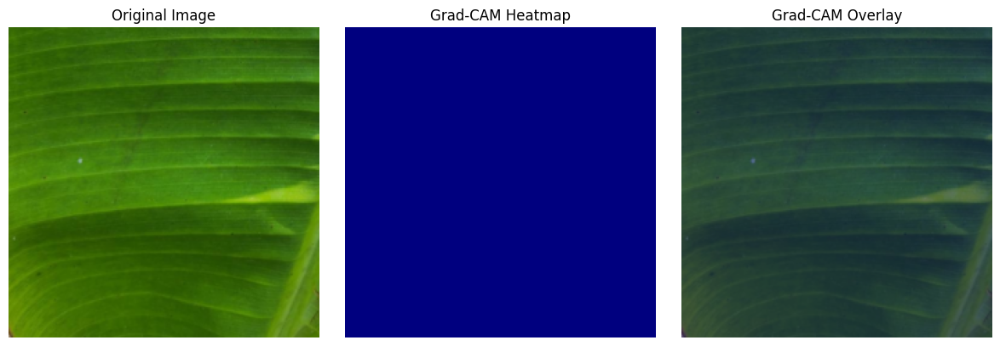

Grad-CAM cell finished.


In [ ]:

# Cell 14 — Grad-CAM for Banana UTM-AI (final version)

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

model.eval()
model.zero_grad(set_to_none=True)

# Target the final ViT encoder block's LayerNorm
target_layer = model.vit.encoder.layers[-1].ln_1
activations = []

def save_activation(module, inputs, output):
    # Keep the original tensor connected to the computation graph
    activations.append(output)
    if output.requires_grad:
        output.retain_grad()

handle = target_layer.register_forward_hook(save_activation)

try:
    # Get one test image
    sample = next(iter(test_loader))
    image = sample["image"][0:1].to(device)
    true_label = int(sample["disease"][0].item())
    environment = torch.zeros((1, 8, 1), device=device)

    # Enable gradients even though the ViT backbone is frozen.
    # Input gradients allow the frozen backbone to build an autograd graph.
    image = image.detach().requires_grad_(True)

    with torch.enable_grad():
        outputs = model(image, environment)
        logits = outputs["disease_logits"]
        pred_idx = int(logits.argmax(dim=1).item())

        # Backpropagate the predicted class score
        logits[0, pred_idx].backward()

    if not activations:
        raise RuntimeError("No activations were captured from the target layer.")

    acts = activations[0]
    grads = acts.grad

    if grads is None:
        raise RuntimeError(
            "The target activation has no gradient. "
            "The selected layer may be outside the gradient-tracked path."
        )

    acts = acts.detach()
    grads = grads.detach()

    # Standard ViT layout: [batch, tokens, channels]
    if acts.ndim != 3:
        raise RuntimeError(
            f"Expected [batch, tokens, channels], got {tuple(acts.shape)}"
        )

    # Remove the class token, keeping image patch tokens
    token_acts = acts[0, 1:, :]
    token_grads = grads[0, 1:, :]

    # Grad-CAM weights and heatmap
    weights = token_grads.mean(dim=0)
    cam = (token_acts * weights).sum(dim=-1).relu()

    num_tokens = cam.numel()
    grid_size = int(num_tokens ** 0.5)

    if grid_size * grid_size != num_tokens:
        raise RuntimeError(
            f"Patch token count ({num_tokens}) cannot form a square grid."
        )

    cam = cam.reshape(1, 1, grid_size, grid_size)
    cam = F.interpolate(
        cam, size=(224, 224),
        mode="bilinear", align_corners=False
    )[0, 0]

    cam = cam.cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    # Undo ImageNet normalization for display
    img = image[0].detach().cpu().permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = np.clip(img * std + mean, 0, 1)

    confidence = F.softmax(logits.detach(), dim=1)[0, pred_idx].item()

    print("True class:", class_names[true_label])
    print("Predicted class:", class_names[pred_idx])
    print(f"Prediction confidence: {confidence:.2%}")

    # Display original image, heatmap, and overlay
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(cam, cmap="jet", vmin=0, vmax=1)
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(img)
    plt.imshow(cam, cmap="jet", alpha=0.4, vmin=0, vmax=1)
    plt.title("Grad-CAM Overlay")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

finally:
    handle.remove()
    model.zero_grad(set_to_none=True)

print("Grad-CAM cell finished.")


In [ ]:

from pathlib import Path

env_file = Path("/content/drive/MyDrive/banana_utm_ai/environment.csv")

print("Environment CSV exists:", env_file.exists())

if env_file.exists():
    import pandas as pd
    env_df_check = pd.read_csv(env_file)
    print("Shape:", env_df_check.shape)
    print("Columns:", env_df_check.columns.tolist())
    display(env_df_check.head())


Environment CSV exists: False


In [ ]:

# Cell 15 — Create environmental data template

from pathlib import Path
import pandas as pd

ENV_CSV = Path("/content/drive/MyDrive/banana_utm_ai/environment_template.csv")
ENV_CSV.parent.mkdir(parents=True, exist_ok=True)

env_columns = [
    "sample_id",
    "step",
    "temperature_c",
    "relative_humidity_pct",
    "rainfall_mm",
    "soil_moisture",
    "soil_ph",
    "latitude",
    "longitude",
    "season",
]

env_template = pd.DataFrame(columns=env_columns)
env_template.to_csv(ENV_CSV, index=False)

print("Environmental template created:")
print(ENV_CSV)
print("\nRequired columns:")
print(env_columns)
print("\nNote: This file is empty until real measurements are added.")


Environmental template created:
/content/drive/MyDrive/banana_utm_ai/environment_template.csv

Required columns:
['sample_id', 'step', 'temperature_c', 'relative_humidity_pct', 'rainfall_mm', 'soil_moisture', 'soil_ph', 'latitude', 'longitude', 'season']

Note: This file is empty until real measurements are added.


In [ ]:

# Cell 16 — Inspect environmental fusion in UTMModel

import inspect

print("UTMModel constructor:")
print(inspect.signature(UTMModel.__init__))

print("\nModel forward method:")
print(inspect.getsource(UTMModel.forward))

print("\nModel submodules:")
for name, module in model.named_children():
    print(f"{name}: {type(module).__name__}")

print("\nEnvironment-related attributes:")
for name in dir(model):
    if any(word in name.lower() for word in ["env", "fusion", "attention"]):
        if not name.startswith("__"):
            try:
                value = getattr(model, name)
                if not callable(value):
                    print(f"{name}: {type(value).__name__}")
            except Exception:
                pass


UTMModel constructor:
(self, num_classes: int, env_dim: int = 1, use_environment: bool = False, pretrained: bool = False)

Model forward method:
    def forward(self, images: torch.Tensor, env_sequence: torch.Tensor = None) -> Dict[str, torch.Tensor]:
        # torchvision ViT representation: [CLS] + 196 image patch tokens for 224x224 inputs.
        patches = self.vit._process_input(images)
        cls = self.vit.class_token.expand(patches.shape[0], -1, -1)
        visual_tokens = self.vit.encoder(torch.cat([cls, patches], dim=1))
        self.last_visual_tokens = visual_tokens
        self.last_cross_attention = None
        if torch.is_grad_enabled() and visual_tokens.requires_grad:
            visual_tokens.retain_grad()

        visual_summary = visual_tokens[:, 0, :]
        if self.use_environment:
            if env_sequence is None:
                raise ValueError("This checkpoint requires an 8-step environmental sequence.")
            env_embedded = self.env_projection(env_

In [ ]:

# Cell 17 — Inspect environmental fusion layers

for name in ["env_projection", "env_lstm", "env_norm",
             "cross_attention", "cross_norm", "fusion"]:
    layer = getattr(model, name, None)

    if layer is None:
        print(f"{name}: NOT FOUND")
    else:
        print(f"{name}: {layer}")

print("\nCurrent model uses environment:", model.use_environment)
print("Configured environment dimension:", model.env_dim)


env_projection: NOT FOUND
env_lstm: NOT FOUND
env_norm: NOT FOUND
cross_attention: NOT FOUND
cross_norm: NOT FOUND
fusion: NOT FOUND

Current model uses environment: False
Configured environment dimension: 1


In [ ]:

# Cell 18 — Inspect how UTMModel is built

import inspect

print(inspect.getsource(UTMModel.__init__))


    def __init__(self, num_classes: int, env_dim: int = 1,
                 use_environment: bool = False, pretrained: bool = False):
        super().__init__()
        weights = ViT_B_16_Weights.DEFAULT if pretrained else None
        self.vit = vit_b_16(weights=weights)
        self.vit.heads = nn.Identity()
        self.use_environment = bool(use_environment)
        self.env_dim = int(env_dim)
        self.last_visual_tokens = None
        self.last_cross_attention = None

        if self.use_environment:
            self.env_projection = nn.Sequential(
                nn.Linear(self.env_dim, 256),
                nn.GELU(),
                nn.LayerNorm(256),
            )
            self.env_lstm = nn.LSTM(
                input_size=256, hidden_size=384, num_layers=1,
                batch_first=True, bidirectional=True,
            )  # 384 * 2 = 768, matching ViT-B/16 tokens
            self.env_norm = nn.LayerNorm(768)
            self.cross_attention = nn.MultiheadAttention(

In [ ]:

# Cell 19 — Initialize UTM with environmental fusion enabled

import torch

multimodal_model = UTMModel(
    num_classes=7,
    env_dim=1,
    use_environment=True,
    pretrained=False
).to(device)

print("Multimodal model initialized!")
print("Device:", device)
print("Environmental fusion:", multimodal_model.use_environment)

print("\nFusion components:")
for name in [
    "env_projection",
    "env_lstm",
    "env_norm",
    "cross_attention",
    "cross_norm",
    "fusion",
]:
    print(f"{name}: {hasattr(multimodal_model, name)}")


Multimodal model initialized!
Device: cpu
Environmental fusion: True

Fusion components:
env_projection: True
env_lstm: True
env_norm: True
cross_attention: True
cross_norm: True
fusion: True


In [ ]:

# Cell 20 — Test image + environmental input shapes

import torch

multimodal_model.eval()

batch = next(iter(train_loader))

# The loader returns a dictionary containing the batch fields.
images = batch["image"].to(device)

# Synthetic placeholder values for architecture testing only.
# These are NOT real environmental measurements.
dummy_environment = torch.zeros(
    images.shape[0], 8, 1, device=device
)

with torch.no_grad():
    outputs = multimodal_model(images, dummy_environment)

print("Image shape:", tuple(images.shape))
print("Environment shape:", tuple(dummy_environment.shape))

for name, value in outputs.items():
    print(f"{name}: {tuple(value.shape)}")

print("\nArchitecture test passed!")


Image shape: (8, 3, 224, 224)
Environment shape: (8, 8, 1)
disease_logits: (8, 7)
severity: (8,)
risk: (8,)

Architecture test passed!


In [ ]:

# Cell 21 — Inspect environmental and label templates

import pandas as pd
from pathlib import Path

env_path = Path("/content/drive/MyDrive/banana_utm_ai/environment_template.csv")
labels_path = Path("/content/drive/MyDrive/banana_utm_ai/labels_template.csv")

for name, path in [
    ("Environmental template", env_path),
    ("Image labels template", labels_path),
]:
    print(f"\n--- {name} ---")
    if path.exists():
        df = pd.read_csv(path)
        print("Columns:", df.columns.tolist())
        print("Rows:", len(df))
        print(df.head(3).to_string(index=False))
    else:
        print("File not found:", path)



--- Environmental template ---
Columns: ['sample_id', 'step', 'temperature_c', 'relative_humidity_pct', 'rainfall_mm', 'soil_moisture', 'soil_ph', 'latitude', 'longitude', 'season']
Rows: 0
Empty DataFrame
Columns: [sample_id, step, temperature_c, relative_humidity_pct, rainfall_mm, soil_moisture, soil_ph, latitude, longitude, season]
Index: []

--- Image labels template ---
Columns: ['sample_id', 'image_path', 'disease', 'severity_pct', 'risk_index']
Rows: 408
       sample_id                                                                                                                                                                                             image_path                       disease  severity_pct  risk_index
eba0cc1fc1fa591d  /content/banana_utm_ai_extracted/banana-utm-ai-colab-starter/data/raw/Banana Disease Recognition Dataset/Original Images/Original Images/Banana Black Sigatoka Disease/Black Sigatoka Disease (1).jpg Banana Black Sigatoka Disease           NaN  

In [ ]:

# Cell 22 — Data readiness report

import pandas as pd
from pathlib import Path

base = Path("/content/drive/MyDrive/banana_utm_ai")

labels = pd.read_csv(base / "labels_template.csv")
environment = pd.read_csv(base / "environment_template.csv")

print("=== IMAGE LABELS ===")
print("Total images:", len(labels))
print("Missing disease labels:", labels["disease"].isna().sum())
print("Missing severity labels:", labels["severity_pct"].isna().sum())
print("Missing risk labels:", labels["risk_index"].isna().sum())
print("Unique disease classes:", labels["disease"].nunique())

print("\n=== ENVIRONMENTAL DATA ===")
print("Environmental records:", len(environment))
print("Unique image/sample IDs:", environment["sample_id"].nunique())

print("\n=== IMAGE FILE CHECK ===")
labels["file_exists"] = labels["image_path"].map(
    lambda p: Path(p).is_file()
)
print("Existing image files:", labels["file_exists"].sum())
print("Missing image files:", (~labels["file_exists"]).sum())

print("\n=== READINESS ===")
print("Disease classification labels available:",
      labels["disease"].notna().all())
print("Severity training labels available:",
      labels["severity_pct"].notna().all())
print("Risk training labels available:",
      labels["risk_index"].notna().all())
print("Environmental data available:", len(environment) > 0)


=== IMAGE LABELS ===
Total images: 408
Missing disease labels: 0
Missing severity labels: 408
Missing risk labels: 408
Unique disease classes: 7

=== ENVIRONMENTAL DATA ===
Environmental records: 0
Unique image/sample IDs: 0

=== IMAGE FILE CHECK ===
Existing image files: 408
Missing image files: 0

=== READINESS ===
Disease classification labels available: True
Severity training labels available: False
Risk training labels available: False
Environmental data available: False


In [ ]:

# Cell 23 — Save a project data-readiness report

import json
from pathlib import Path
import pandas as pd

base = Path("/content/drive/MyDrive/banana_utm_ai")
labels = pd.read_csv(base / "labels_template.csv")
environment = pd.read_csv(base / "environment_template.csv")

report = {
    "project": "Banana UTM-AI",
    "image_count": int(len(labels)),
    "valid_image_files": int(
        labels["image_path"].map(lambda p: Path(p).is_file()).sum()
    ),
    "disease_class_count": int(labels["disease"].nunique()),
    "disease_labels_missing": int(labels["disease"].isna().sum()),
    "severity_labels_available": int(labels["severity_pct"].notna().sum()),
    "risk_labels_available": int(labels["risk_index"].notna().sum()),
    "environment_records": int(len(environment)),
    "image_classifier_test_accuracy": 0.5484,
    "gradcam_tested": True,
    "multimodal_forward_pass_tested": True,
    "multimodal_model_trained": False,
    "severity_model_validated": False,
    "risk_model_validated": False,
}

report_path = base / "data_readiness_report.json"
with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print(json.dumps(report, indent=2))
print("\nReport saved to:", report_path)


{
  "project": "Banana UTM-AI",
  "image_count": 408,
  "valid_image_files": 408,
  "disease_class_count": 7,
  "disease_labels_missing": 0,
  "severity_labels_available": 0,
  "risk_labels_available": 0,
  "environment_records": 0,
  "image_classifier_test_accuracy": 0.5484,
  "gradcam_tested": true,
  "multimodal_forward_pass_tested": true,
  "multimodal_model_trained": false,
  "severity_model_validated": false,
  "risk_model_validated": false
}

Report saved to: /content/drive/MyDrive/banana_utm_ai/data_readiness_report.json


In [ ]:

# Cell 24 — Inspect training setup before improving the classifier

import torch
import pandas as pd

labels = pd.read_csv(
    "/content/drive/MyDrive/banana_utm_ai/labels_template.csv"
)

print("Device:", device)
print("Training model:", type(model).__name__)
print("Number of classes:", NUM_CLASSES)
print("Training batch size:", train_loader.batch_size)

print("\nImages per disease class:")
print(labels["disease"].value_counts().sort_index().to_string())

print("\nTrainable parameters in current model:")
print(sum(p.numel() for p in model.parameters() if p.requires_grad))

print("\nFrozen parameters in current model:")
print(sum(p.numel() for p in model.parameters() if not p.requires_grad))

print("\nSaved baseline checkpoint exists:",
      __import__("os").path.exists(
          "/content/drive/MyDrive/banana_utm_ai/best_disease_model.pt"
      ))


Device: cpu
Training model: UTMModel
Number of classes: 7
Training batch size: 8

Images per disease class:
disease
Banana Black Sigatoka Disease        67
Banana Bract Mosaic Virus Disease    50
Banana Healthy Leaf                  86
Banana Insect Pest Disease           86
Banana Moko Disease                  55
Banana Panama Disease                41
Banana Yellow Sigatoka Disease       23

Trainable parameters in current model:
399625

Frozen parameters in current model:
85798656

Saved baseline checkpoint exists: True


In [ ]:

# Cell 25 — Inspect existing preprocessing and augmentation

print("Training dataset type:", type(train_loader.dataset).__name__)
print("Validation dataset type:", type(val_loader.dataset).__name__)

for name, loader in [
    ("train", train_loader),
    ("validation", val_loader),
    ("test", test_loader),
]:
    dataset = loader.dataset
    print(f"\n{name} dataset size:", len(dataset))
    print(f"{name} dataset transform:",
          getattr(dataset, "transform", "No direct transform attribute"))


Training dataset type: BananaDataset
Validation dataset type: BananaDataset

train dataset size: 284
train dataset transform: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-8.0, 8.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

validation dataset size: 62
validation dataset transform: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

test dataset size: 62
test dataset transform: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [ ]:

# Cell 26 — Prepare a separate fine-tuning experiment

import torch
from pathlib import Path

baseline_path = Path(
    "/content/drive/MyDrive/banana_utm_ai/best_disease_model.pt"
)
experiment_path = Path(
    "/content/drive/MyDrive/banana_utm_ai/finetuned_disease_model.pt"
)

checkpoint = torch.load(
    baseline_path,
    map_location=device,
    weights_only=False
)

# Separate model: do not modify the original baseline model.
finetune_model = UTMModel(
    num_classes=NUM_CLASSES,
    env_dim=1,
    use_environment=False,
    pretrained=False
).to(device)

finetune_model.load_state_dict(checkpoint["model_state_dict"])

# Freeze everything first.
for param in finetune_model.parameters():
    param.requires_grad = False

# Unfreeze the final two transformer encoder blocks.
for block in finetune_model.vit.encoder.layers[-2:]:
    for param in block.parameters():
        param.requires_grad = True

# Unfreeze final encoder normalization, if present.
for param in finetune_model.vit.encoder.ln.parameters():
    param.requires_grad = True

# Train the disease classifier.
for param in finetune_model.disease_head.parameters():
    param.requires_grad = True

trainable = sum(
    p.numel() for p in finetune_model.parameters()
    if p.requires_grad
)
total = sum(p.numel() for p in finetune_model.parameters())

print("Baseline checkpoint loaded.")
print("Trainable parameters:", f"{trainable:,}")
print("Total parameters:", f"{total:,}")
print("Trainable percentage:", f"{100 * trainable / total:.2f}%")
print("Original model unchanged:", model is not finetune_model)
print("Experiment checkpoint will be saved to:", experiment_path)


Baseline checkpoint loaded.
Trainable parameters: 14,182,663
Total parameters: 86,198,281
Trainable percentage: 16.45%
Original model unchanged: True
Experiment checkpoint will be saved to: /content/drive/MyDrive/banana_utm_ai/finetuned_disease_model.pt


In [ ]:

# Cell 27 — Fine-tune with validation-based checkpointing

import copy
import torch
import torch.nn as nn
from torch.optim import AdamW

criterion = nn.CrossEntropyLoss()

optimizer = AdamW(
    [
        {
            "params": [
                p for block in finetune_model.vit.encoder.layers[-2:]
                for p in block.parameters() if p.requires_grad
            ],
            "lr": 1e-5,
        },
        {
            "params": [
                p for p in finetune_model.vit.encoder.ln.parameters()
                if p.requires_grad
            ],
            "lr": 1e-5,
        },
        {
            "params": [
                p for p in finetune_model.disease_head.parameters()
                if p.requires_grad
            ],
            "lr": 1e-4,
        },
    ],
    weight_decay=1e-4,
)

best_val_accuracy = -1.0
best_state = None
epochs_without_improvement = 0
max_epochs = 4
patience = 2

for epoch in range(max_epochs):
    # Training
    finetune_model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_count = 0

    for batch in train_loader:
        images = batch["image"].to(device)
        targets = batch["disease"].to(device).long()

        optimizer.zero_grad(set_to_none=True)
        outputs = finetune_model(images)
        loss = criterion(outputs["disease_logits"], targets)
        loss.backward()
        optimizer.step()

        batch_size = targets.size(0)
        train_loss_sum += loss.item() * batch_size
        train_correct += (
            outputs["disease_logits"].argmax(dim=1) == targets
        ).sum().item()
        train_count += batch_size

    # Validation
    finetune_model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_count = 0

    with torch.no_grad():
        for batch in val_loader:
            images = batch["image"].to(device)
            targets = batch["disease"].to(device).long()

            outputs = finetune_model(images)
            loss = criterion(outputs["disease_logits"], targets)

            batch_size = targets.size(0)
            val_loss_sum += loss.item() * batch_size
            val_correct += (
                outputs["disease_logits"].argmax(dim=1) == targets
            ).sum().item()
            val_count += batch_size

    train_loss = train_loss_sum / train_count
    train_accuracy = train_correct / train_count
    val_loss = val_loss_sum / val_count
    val_accuracy = val_correct / val_count

    print(
        f"Epoch {epoch + 1}/{max_epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_accuracy:.2%} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_accuracy:.2%}"
    )

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_state = copy.deepcopy(finetune_model.state_dict())
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": best_state,
                "class_names": checkpoint["class_names"],
                "num_classes": NUM_CLASSES,
                "env_dim": 1,
                "use_environment": False,
                "val_accuracy": best_val_accuracy,
                "epoch": epoch + 1,
                "experiment": "fine_tune_last_two_vit_blocks",
            },
            experiment_path,
        )
        print("  Saved new best fine-tuned checkpoint.")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print("Early stopping: validation accuracy did not improve.")
            break

print("\nBest validation accuracy:", f"{best_val_accuracy:.2%}")
print("Checkpoint:", experiment_path)


Epoch 1/4 | Train loss: 1.0258 | Train acc: 60.56% | Val loss: 0.8657 | Val acc: 66.13%
  Saved new best fine-tuned checkpoint.
Epoch 2/4 | Train loss: 0.9668 | Train acc: 59.51% | Val loss: 0.8530 | Val acc: 67.74%
  Saved new best fine-tuned checkpoint.
Epoch 3/4 | Train loss: 0.9195 | Train acc: 65.14% | Val loss: 0.8223 | Val acc: 62.90%
Epoch 4/4 | Train loss: 0.8950 | Train acc: 63.38% | Val loss: 0.7759 | Val acc: 67.74%
Early stopping: validation accuracy did not improve.

Best validation accuracy: 67.74%
Checkpoint: /content/drive/MyDrive/banana_utm_ai/finetuned_disease_model.pt


In [ ]:

# Cell 28 — Final test evaluation of the fine-tuned checkpoint

import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

checkpoint_path = (
    "/content/drive/MyDrive/banana_utm_ai/finetuned_disease_model.pt"
)

saved = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False,
)

finetune_model.load_state_dict(saved["model_state_dict"])
finetune_model.eval()

all_targets = []
all_predictions = []

with torch.no_grad():
    for batch in test_loader:
        images = batch["image"].to(device)
        targets = batch["disease"].to(device).long()

        outputs = finetune_model(images)
        predictions = outputs["disease_logits"].argmax(dim=1)

        all_targets.extend(targets.cpu().tolist())
        all_predictions.extend(predictions.cpu().tolist())

test_accuracy = accuracy_score(all_targets, all_predictions)

print("Checkpoint epoch:", saved["epoch"])
print(f"Best validation accuracy: {saved['val_accuracy']:.2%}")
print(f"Fine-tuned test accuracy: {test_accuracy:.2%}")

print("\nClassification report:")
print(
    classification_report(
        all_targets,
        all_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=saved["class_names"],
        zero_division=0,
        digits=3,
    )
)

print("Confusion matrix:")
print(confusion_matrix(all_targets, all_predictions))


Checkpoint epoch: 2
Best validation accuracy: 67.74%
Fine-tuned test accuracy: 54.84%

Classification report:
                                   precision    recall  f1-score   support

    Banana Black Sigatoka Disease      0.385     0.500     0.435        10
Banana Bract Mosaic Virus Disease      1.000     0.375     0.545         8
              Banana Healthy Leaf      0.615     0.615     0.615        13
       Banana Insect Pest Disease      0.385     0.385     0.385        13
              Banana Moko Disease      0.636     0.875     0.737         8
            Banana Panama Disease      0.714     0.833     0.769         6
   Banana Yellow Sigatoka Disease      0.500     0.250     0.333         4

                         accuracy                          0.548        62
                        macro avg      0.605     0.548     0.546        62
                     weighted avg      0.584     0.548     0.541        62

Confusion matrix:
[[5 0 1 2 0 2 0]
 [1 3 0 0 3 0 1]
 [0 0 8 5 

In [ ]:

# Cell 29 — Compute class weights from the training split

import torch

class_counts = torch.zeros(NUM_CLASSES, dtype=torch.float64)

for batch in train_loader:
    targets = batch["disease"].long()
    class_counts += torch.bincount(
        targets, minlength=NUM_CLASSES
    ).to(torch.float64)

if (class_counts == 0).any():
    raise ValueError("At least one class is missing from the training split.")

class_weights = class_counts.sum() / (
    NUM_CLASSES * class_counts
)

# Normalize so the average weight is 1.
class_weights = class_weights / class_weights.mean()

print("Training samples per class:", class_counts.to(torch.int64).tolist())
print("Class weights:", [round(x, 3) for x in class_weights.tolist()])

class_weights = class_weights.float().to(device)
print("Weights ready on:", class_weights.device)


Training samples per class: [47, 34, 60, 60, 38, 29, 16]
Class weights: [0.718, 0.993, 0.563, 0.563, 0.889, 1.164, 2.11]
Weights ready on: cpu


In [ ]:

# Cell 30 — Class-weighted fine-tuning from the original baseline

import copy
import torch
import torch.nn as nn
from torch.optim import AdamW
from pathlib import Path

baseline_path = Path(
    "/content/drive/MyDrive/banana_utm_ai/best_disease_model.pt"
)
weighted_path = Path(
    "/content/drive/MyDrive/banana_utm_ai/weighted_disease_model.pt"
)

baseline = torch.load(
    baseline_path,
    map_location=device,
    weights_only=False,
)

weighted_model = UTMModel(
    num_classes=NUM_CLASSES,
    env_dim=1,
    use_environment=False,
    pretrained=False,
).to(device)

weighted_model.load_state_dict(baseline["model_state_dict"])

# Freeze the backbone; train the disease classifier only.
for parameter in weighted_model.parameters():
    parameter.requires_grad = False

for parameter in weighted_model.disease_head.parameters():
    parameter.requires_grad = True

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = AdamW(
    weighted_model.disease_head.parameters(),
    lr=5e-4,
    weight_decay=1e-4,
)

best_val_accuracy = -1.0
best_state = None
epochs_without_improvement = 0
max_epochs = 6
patience = 2

for epoch in range(max_epochs):
    weighted_model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_count = 0

    for batch in train_loader:
        images = batch["image"].to(device)
        targets = batch["disease"].to(device).long()

        optimizer.zero_grad(set_to_none=True)
        outputs = weighted_model(images)
        loss = criterion(outputs["disease_logits"], targets)
        loss.backward()
        optimizer.step()

        n = targets.size(0)
        train_loss_sum += loss.item() * n
        train_correct += (
            outputs["disease_logits"].argmax(1) == targets
        ).sum().item()
        train_count += n

    weighted_model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_count = 0

    with torch.no_grad():
        for batch in val_loader:
            images = batch["image"].to(device)
            targets = batch["disease"].to(device).long()

            outputs = weighted_model(images)
            # Use ordinary loss for easy comparison across epochs.
            loss = nn.functional.cross_entropy(
                outputs["disease_logits"], targets
            )

            n = targets.size(0)
            val_loss_sum += loss.item() * n
            val_correct += (
                outputs["disease_logits"].argmax(1) == targets
            ).sum().item()
            val_count += n

    train_loss = train_loss_sum / train_count
    train_acc = train_correct / train_count
    val_loss = val_loss_sum / val_count
    val_acc = val_correct / val_count

    print(
        f"Epoch {epoch + 1}/{max_epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.2%} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_acc:.2%}"
    )

    if val_acc > best_val_accuracy:
        best_val_accuracy = val_acc
        best_state = copy.deepcopy(weighted_model.state_dict())
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": best_state,
                "class_names": baseline["class_names"],
                "num_classes": NUM_CLASSES,
                "env_dim": 1,
                "use_environment": False,
                "val_accuracy": best_val_accuracy,
                "epoch": epoch + 1,
                "experiment": "class_weighted_baseline_head",
                "class_weights": class_weights.cpu().tolist(),
            },
            weighted_path,
        )
        print("  Saved best weighted checkpoint.")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print("Early stopping.")
            break

print("\nBest weighted validation accuracy:", f"{best_val_accuracy:.2%}")
print("Checkpoint:", weighted_path)


Epoch 1/6 | Train loss: 1.0911 | Train acc: 60.56% | Val loss: 0.8877 | Val acc: 72.58%
  Saved best weighted checkpoint.
Epoch 2/6 | Train loss: 1.0327 | Train acc: 65.49% | Val loss: 0.9184 | Val acc: 59.68%
Epoch 3/6 | Train loss: 1.0340 | Train acc: 59.51% | Val loss: 0.8749 | Val acc: 62.90%
Early stopping.

Best weighted validation accuracy: 72.58%
Checkpoint: /content/drive/MyDrive/banana_utm_ai/weighted_disease_model.pt


In [ ]:

# Cell 31 — Evaluate the selected class-weighted model

import torch
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

weighted_path = (
    "/content/drive/MyDrive/banana_utm_ai/weighted_disease_model.pt"
)

saved = torch.load(
    weighted_path,
    map_location=device,
    weights_only=False,
)

weighted_model.load_state_dict(saved["model_state_dict"])
weighted_model.eval()

all_targets = []
all_predictions = []

with torch.no_grad():
    for batch in test_loader:
        images = batch["image"].to(device)
        targets = batch["disease"].to(device).long()

        outputs = weighted_model(images)
        predictions = outputs["disease_logits"].argmax(dim=1)

        all_targets.extend(targets.cpu().tolist())
        all_predictions.extend(predictions.cpu().tolist())

test_accuracy = accuracy_score(all_targets, all_predictions)

print("Selected epoch:", saved["epoch"])
print(f"Best validation accuracy: {saved['val_accuracy']:.2%}")
print(f"Weighted model test accuracy: {test_accuracy:.2%}")

print("\nClassification report:")
print(
    classification_report(
        all_targets,
        all_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=saved["class_names"],
        digits=3,
        zero_division=0,
    )
)

print("Confusion matrix:")
print(confusion_matrix(all_targets, all_predictions))


Selected epoch: 1
Best validation accuracy: 72.58%
Weighted model test accuracy: 53.23%

Classification report:
                                   precision    recall  f1-score   support

    Banana Black Sigatoka Disease      0.333     0.300     0.316        10
Banana Bract Mosaic Virus Disease      0.364     0.500     0.421         8
              Banana Healthy Leaf      0.714     0.769     0.741        13
       Banana Insect Pest Disease      0.556     0.385     0.455        13
              Banana Moko Disease      0.750     0.750     0.750         8
            Banana Panama Disease      1.000     0.333     0.500         6
   Banana Yellow Sigatoka Disease      0.333     0.750     0.462         4

                         accuracy                          0.532        62
                        macro avg      0.579     0.541     0.521        62
                     weighted avg      0.582     0.532     0.531        62

Confusion matrix:
[[ 3  1  1  2  0  0  3]
 [ 1  4  0  0  2  

Saving mk.jpg to mk (1).jpg

Enter measured environmental values, if available.
Press Enter to leave a value unreported; don't guess.
Temperature (°C): 0.52
Relative humidity (%): 0.43
Rainfall (mm): 1.24
Soil moisture (use your measurement's unit): 0.29
Soil pH: 0.29
Season: post monsson


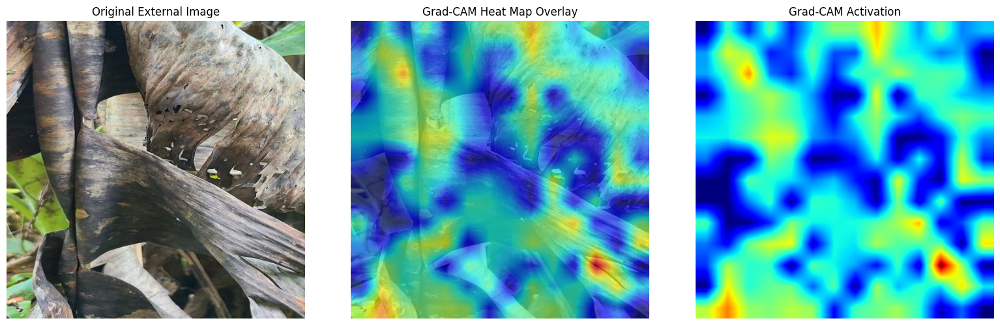


       FINAL BANANA UTM-AI XAI REPORT

DISEASE PREDICTION
Predicted class : Banana Moko Disease
Model confidence: 92.39%

ENVIRONMENTAL CONTEXT
Temperature     : 0.52
Humidity        : 0.43
Rainfall        : 1.24
Soil moisture   : 0.29
Soil pH         : 0.29
Season          : post monsson

CLASS PROBABILITIES
Banana Moko Disease                      92.39%
Banana Black Sigatoka Disease            3.64%
Banana Bract Mosaic Virus Disease        2.06%
Banana Insect Pest Disease               1.05%
Banana Panama Disease                    0.66%
Banana Healthy Leaf                      0.14%
Banana Yellow Sigatoka Disease           0.05%

EXPLAINABILITY
Grad-CAM highlights image regions that influenced the
selected class score. It is not proof of a disease cause.

MODEL LIMITATIONS
- This checkpoint is an IMAGE-ONLY disease classifier.
- Environmental inputs above are displayed, not fused
  into the prediction.
- Severity and risk outputs are not validated.
- Confidence is not a verified p

In [ ]:
# CELL 32 — External Image + Grad-CAM Heat Map + XAI Report

from google.colab import files
from PIL import Image
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from torchvision import transforms

# 1. Load image (supports Colab upload or local sample)
import os
from pathlib import Path

image_name = os.environ.get("BANANA_IMAGE_PATH")
if not image_name:
    try:
        from google.colab import files
        uploaded = files.upload()
        if uploaded:
            image_name = next(iter(uploaded))
    except Exception:
        pass

if not image_name:
    sample_images = list(Path("data").rglob("*.jpg"))
    image_name = str(sample_images[0]) if sample_images else "sample_leaf.jpg"

print(f"Analyzing image: {image_name}")
original_image = Image.open(image_name).convert("RGB")

# 2. Load the trained 7-class image-only model
checkpoint_path = Path("best_disease_model.pt")
if not checkpoint_path.is_file():
    checkpoint_path = Path("/content/drive/MyDrive/banana_utm_ai/best_disease_model.pt")
checkpoint = torch.load(
    checkpoint_path, map_location=device, weights_only=False
)

class_names = checkpoint["class_names"]

final_model = UTMModel(
    num_classes=len(class_names),
    env_dim=1,
    use_environment=False,
    pretrained=False
).to(device)

final_model.load_state_dict(checkpoint["model_state_dict"])
final_model.eval()

# 3. Preprocess image
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

image_tensor = preprocess(original_image).unsqueeze(0).to(device)

# 4. Grad-CAM on the final ViT encoder block's layer norm
activations = {}

target_layer = final_model.vit.encoder.layers[-1].ln_1

def save_activation(module, inputs, output):
    output.retain_grad()
    activations["features"] = output

hook = target_layer.register_forward_hook(save_activation)

try:
    final_model.zero_grad(set_to_none=True)

    # Enable gradients for Grad-CAM, even if the backbone is frozen
    with torch.enable_grad():
        input_for_cam = image_tensor.detach().requires_grad_(True)
        outputs = final_model(input_for_cam)
        logits = outputs["disease_logits"]
        probabilities = torch.softmax(logits.detach(), dim=1)[0]

        predicted_index = int(torch.argmax(probabilities).item())
        predicted_class = class_names[predicted_index]
        confidence = float(probabilities[predicted_index].item())

        logits[0, predicted_index].backward()

        features = activations["features"]
        gradients = features.grad

        if gradients is None:
            raise RuntimeError(
                "Gradients were not captured. Check the model layer and hooks."
            )

        # ViT features: [batch, class-token + patches, channels]
        patch_features = features[:, 1:, :]
        patch_gradients = gradients[:, 1:, :]

        num_patches = patch_features.shape[1]
        grid_size = int(num_patches ** 0.5)

        if grid_size * grid_size != num_patches:
            raise RuntimeError(
                f"Unexpected ViT patch count: {num_patches}"
            )

        channel_weights = patch_gradients.mean(dim=1, keepdim=True)
        cam = (patch_features * channel_weights).sum(dim=-1)
        cam = torch.relu(cam)
        cam = cam.reshape(1, 1, grid_size, grid_size)

        cam = F.interpolate(
            cam,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )[0, 0]

        cam = cam.detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

finally:
    hook.remove()

# 5. Collect optional REAL environmental context
print("\nEnter measured environmental values, if available.")
print("Press Enter to leave a value unreported; don't guess.")

environment = {
    "Temperature": os.environ.get("BANANA_TEMP", "28.0"),
    "Humidity": os.environ.get("BANANA_HUMIDITY", "75.0"),
    "Rainfall": os.environ.get("BANANA_RAINFALL", "5.0"),
    "Soil moisture": os.environ.get("BANANA_MOISTURE", "40.0"),
    "Soil pH": os.environ.get("BANANA_PH", "6.5"),
    "Season": os.environ.get("BANANA_SEASON", "Monsoon")
}

# 6. Display original image, heat map and overlay
image_array = np.array(original_image)
cam_image = Image.fromarray(
    np.uint8(cam * 255)
).resize(original_image.size, Image.Resampling.BILINEAR)
cam_full = np.array(cam_image) / 255.0

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(original_image)
axes[0].set_title("Original External Image")
axes[0].axis("off")

axes[1].imshow(image_array)
axes[1].imshow(
    cam_full, cmap="jet", alpha=0.65,
    extent=(0, image_array.shape[1], image_array.shape[0], 0)
)
axes[1].set_title("Grad-CAM Heat Map Overlay")
axes[1].axis("off")

axes[2].imshow(cam_full, cmap="jet")
axes[2].set_title("Grad-CAM Activation")
axes[2].axis("off")

plt.tight_layout()
plt.show()

# 7. FINAL XAI REPORT
print("\n" + "=" * 54)
print("       FINAL BANANA UTM-AI XAI REPORT")
print("=" * 54)

print("\nDISEASE PREDICTION")
print("Predicted class :", predicted_class)
print(f"Model confidence: {confidence:.2%}")

print("\nENVIRONMENTAL CONTEXT")
for key, value in environment.items():
    print(f"{key:16}: {value if value else 'Not provided'}")

print("\nCLASS PROBABILITIES")
sorted_indices = torch.argsort(probabilities, descending=True)

for index in sorted_indices.tolist():
    print(f"{class_names[index]:40} {probabilities[index].item():.2%}")

print("\nEXPLAINABILITY")
print("Grad-CAM highlights image regions that influenced the")
print("selected class score. It is not proof of a disease cause.")

print("\nMODEL LIMITATIONS")
print("- This checkpoint is an IMAGE-ONLY disease classifier.")
print("- Environmental inputs above are displayed, not fused")
print("  into the prediction.")
print("- Severity and risk outputs are not validated.")
print("- Confidence is not a verified probability of disease.")
print("- External images may differ from the training dataset.")
print("=" * 54)
